# Chapter 8 — Trajectory Generation

Chapters 5 to 7 answered *where*: forward kinematics gives the gripper pose for a set of
joint angles, the Jacobian relates their velocities, and inverse kinematics finds the
joint angles for a desired gripper pose. A task such as pick and place is therefore a list
of poses: above the block, at the block, lifted, above the goal, at the goal. This chapter
answers the question in between:

> **Trajectory generation:** given the poses (or joint angles) a robot must pass through,
> and limits on how fast it may move, find the joint angles as a function of time,
> $\boldsymbol\theta(t)$, so that the robot moves smoothly, stays within its limits, and
> finishes quickly.

Two decisions shape every trajectory. The **path** is the geometric curve the robot
follows: a straight line in joint space, a straight line for the gripper, or a curve
through several waypoints. The **timing** is how fast it moves along that path: when it
starts, how quickly it speeds up, and when it stops. Good timing makes the motion smooth
and keeps the motors within their limits; good path choices keep the gripper away from the
table and from objects.

| Section | Topic |
|---------|-------|
| 8.1 | Paths, trajectories, and time scaling |
| 8.2 | Point-to-point polynomials: linear, cubic, quintic |
| 8.3 | Trapezoidal velocity profiles: the fastest move under speed and acceleration limits |
| 8.4 | Via points: moving through waypoints without stopping |
| 8.5 | Straight-line trajectories in task space |
| 8.6 | From a trajectory to motor commands |
| 8.7 | Putting it together: a fast pick and place on the SO-ARM101 |

**Notation** (same as Chapters 5 to 7). $\boldsymbol\theta$ is the vector of joint
variables; a single joint is $\theta$. A trajectory runs from $\boldsymbol\theta_0$ at
$t = 0$ to $\boldsymbol\theta_f$ at $t = T$, and $\Delta = \theta_f - \theta_0$ is the
distance one joint travels. Dots are time derivatives: $\dot\theta$ is velocity,
$\ddot\theta$ acceleration. The formulas work in any units. The one-joint examples use
degrees, because they are easier to read; the robot code works in radians and prints
degrees, as in Chapter 7. In the code, a joint vector is called `q`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace
from ipywidgets import interact, FloatSlider
%matplotlib inline

np.set_printoptions(precision=4, suppress=True)

### Tools and robots from Chapters 5 to 7

The next cell collects what we reuse: the **planar 2R arm** ($L_1 = 1$, $L_2 = 0.7$) with its
forward kinematics, Jacobian and closed-form IK, and the **SO-ARM101** with its forward
kinematics (the body frames of its MuJoCo model, Chapter 7) and the analytical position + pitch
IK `so101_ik` of Section 7.4.3. Run the cell and move on.

In [2]:
# ── Planar 2R arm (Chapters 3, 5 and 6): L1 = 1, L2 = 0.7 ─────────────────────
L1_2R, L2_2R = 1.0, 0.7


def fk_2R(q, L1=L1_2R, L2=L2_2R):
    # Elbow and tip positions of the planar 2R arm; q = (θ1, θ2) in rad (q may be an (N, 2) array)
    q = np.asarray(q, float)
    t1, t12 = q[..., 0], q[..., 0] + q[..., 1]
    elbow = np.stack([L1 * np.cos(t1), L1 * np.sin(t1)], axis=-1)
    tip = elbow + np.stack([L2 * np.cos(t12), L2 * np.sin(t12)], axis=-1)
    return elbow, tip


def jacobian_2R(q, L1=L1_2R, L2=L2_2R):
    # 2x2 Jacobian of the tip position (Chapter 6)
    t1, t12 = q[0], q[0] + q[1]
    return np.array([[-L1 * np.sin(t1) - L2 * np.sin(t12), -L2 * np.sin(t12)],
                     [ L1 * np.cos(t1) + L2 * np.cos(t12),  L2 * np.cos(t12)]])


def ik_2R(x, y, L1=L1_2R, L2=L2_2R, elbow=+1):
    # Closed-form 2R inverse kinematics (Chapter 7, Section 7.1); elbow=+1 gives θ2 > 0
    c2 = (x**2 + y**2 - L1**2 - L2**2) / (2 * L1 * L2)
    th2 = elbow * np.arccos(np.clip(c2, -1, 1))
    th1 = np.arctan2(y, x) - np.arctan2(L2 * np.sin(th2), L1 + L2 * np.cos(th2))
    return np.array([th1, th2])


def draw_2R(ax, q, color='0.4', alpha=1.0, lw=4):
    # Draw the 2R arm as two thick links
    elbow, tip = fk_2R(q)
    pts = np.array([[0, 0], elbow, tip])
    ax.plot(*pts.T, '-', color=color, lw=lw, alpha=alpha, solid_capstyle='round')
    ax.plot(*pts[:2].T, 'o', color=color, ms=5, alpha=alpha)


# ── SO-ARM101: body frames of the MuJoCo model (Chapter 7, Section 7.4) ────────
def Rot(axis, theta):
    c, s = np.cos(theta), np.sin(theta)
    R = {'x': [[1, 0, 0], [0, c, -s], [0, s, c]],
         'y': [[c, 0, s], [0, 1, 0], [-s, 0, c]],
         'z': [[c, -s, 0], [s, c, 0], [0, 0, 1]]}[axis]
    T = np.eye(4)
    T[:3, :3] = R
    return T


def HTM(R, o):
    T = np.eye(4)
    T[:3, :3], T[:3, 3] = R, o
    return T


def quat_to_R(w, x, y, z):
    n = np.sqrt(w*w + x*x + y*y + z*z)
    w, x, y, z = w / n, x / n, y / n, z / n
    return np.array([[1 - 2*(y*y + z*z), 2*(x*y - w*z),     2*(x*z + w*y)],
                     [2*(x*y + w*z),     1 - 2*(x*x + z*z), 2*(y*z - w*x)],
                     [2*(x*z - w*y),     2*(y*z + w*x),     1 - 2*(x*x + y*y)]])


def wrap(angle):
    return (np.asarray(angle) + np.pi) % (2 * np.pi) - np.pi


SO101_LINKS = [
    ('shoulder_pan',  [0.0388353, 0.0, 0.0624],          (0, 0, -1, 0)),
    ('shoulder_lift', [-0.0303992, -0.0182778, -0.0542], (0.5, -0.5, -0.5, -0.5)),
    ('elbow_flex',    [-0.11257, -0.028, 0.0],           (0.707107, 0, 0, 0.707107)),
    ('wrist_flex',    [-0.1349, 0.0052, 0.0],            (0.707107, 0, 0, -0.707107)),
    ('wrist_roll',    [0.0, -0.0611, 0.0181],            (0.0172091, -0.0172091, 0.706897, 0.706897)),
]
SO101_Te5 = HTM(quat_to_R(0.707107, 0, 0.707107, 0), [-0.0079, -0.000218121, -0.0981274])
SO101_LIMITS_DEG = [(-110, 110), (-100, 100), (-96.8, 96.8), (-95, 95), (-157.2, 162.8)]


class SO101:
    def __init__(self):
        self.name, self.n = 'SO-ARM101', 5
        self.joint_names = [name for name, _, _ in SO101_LINKS]
        self.home = [HTM(quat_to_R(*quat), o) for _, o, quat in SO101_LINKS]
        self.lo = np.radians([lo for lo, _ in SO101_LIMITS_DEG])
        self.hi = np.radians([hi for _, hi in SO101_LIMITS_DEG])

    def frames(self, q):
        T, out = np.eye(4), {'0': np.eye(4)}
        for i, (T_home, qi) in enumerate(zip(self.home, q)):
            T = T @ T_home @ Rot('z', qi)
            out[str(i + 1)] = T
        out['e'] = T @ SO101_Te5
        return out

    def fk(self, q):
        return self.frames(q)['e']

    def within_limits(self, q, tol=1e-9):
        return bool(np.all(q >= self.lo - tol) and np.all(q <= self.hi + tol))


so101 = SO101()


def heading(v):
    return np.arctan2(v[1], v[0])


def _arm_plane_geometry():
    F0 = so101.frames(np.zeros(5))
    xp = F0['1'][0, 3]
    S, E, W, P = [np.array([F0[k][0, 3] - xp, F0[k][2, 3]]) for k in ('2', '3', '4', 'e')]
    return SimpleNamespace(xp=xp, S=S, L1=np.linalg.norm(E - S), L2=np.linalg.norm(W - E),
                           L3=np.linalg.norm(P - W), alpha1=heading(E - S),
                           gamma0=np.pi + heading(W - E) - heading(E - S), delta=heading(P - W))


geo = _arm_plane_geometry()


def so101_ik(p_d, phi_d, theta5=0.0, elbow='up'):
    # Analytical position + pitch IK of Chapter 7, Section 7.4.3 (rad). None if out of reach.
    x, y, z = p_d
    theta1 = -np.arctan2(y, x - geo.xp)
    r = np.hypot(x - geo.xp, y)
    W = np.array([r, z]) - geo.L3 * np.array([np.cos(phi_d + geo.delta), np.sin(phi_d + geo.delta)])
    D = np.linalg.norm(W - geo.S)
    c = (geo.L1**2 + geo.L2**2 - D**2) / (2 * geo.L1 * geo.L2)
    if abs(c) > 1:
        return None
    gamma = np.arccos(c)
    sigma = np.arccos(np.clip((geo.L1**2 + D**2 - geo.L2**2) / (2 * geo.L1 * D), -1, 1))
    psi_sw = heading(W - geo.S)
    if elbow == 'up':
        theta3, theta2 = geo.gamma0 - gamma, geo.alpha1 - (psi_sw + sigma)
    else:
        theta3, theta2 = geo.gamma0 + gamma - 2 * np.pi, geo.alpha1 - (psi_sw - sigma)
    theta4 = -phi_d - theta2 - theta3
    return wrap(np.array([theta1, theta2, theta3, theta4, theta5]))


print('Ready: planar 2R arm (fk_2R, jacobian_2R, ik_2R) and SO-ARM101 (so101.fk, so101_ik).')

Ready: planar 2R arm (fk_2R, jacobian_2R, ik_2R) and SO-ARM101 (so101.fk, so101_ik).


## 8.1  Paths, Trajectories, and Time Scaling

A **path** is a curve through the space of joint angles, written with a path parameter
$s$ that runs from 0 at the start to 1 at the end: $\boldsymbol\theta(s)$, $s \in [0, 1]$.
The simplest path is the straight line in joint space,

$$\boldsymbol\theta(s) = \boldsymbol\theta_0 + s\,(\boldsymbol\theta_f - \boldsymbol\theta_0).$$

A **trajectory** adds timing: a **time scaling** $s(t)$ says how far along the path the robot
is at time $t$, with $s(0) = 0$ and $s(T) = 1$. The trajectory is
$\boldsymbol\theta(t) = \boldsymbol\theta(s(t))$, and by the chain rule

$$\dot{\boldsymbol\theta} = \frac{d\boldsymbol\theta}{ds}\,\dot s, \qquad
\ddot{\boldsymbol\theta} = \frac{d\boldsymbol\theta}{ds}\,\ddot s + \frac{d^2\boldsymbol\theta}{ds^2}\,\dot s^2 .$$

On the straight line, $d\boldsymbol\theta/ds = \boldsymbol\theta_f - \boldsymbol\theta_0$ and
$d^2\boldsymbol\theta/ds^2 = \mathbf{0}$, so every joint moves in proportion to the
distance it has to travel. Writing $\Delta_i = \theta_{f,i} - \theta_{0,i}$ for the distance
joint $i$ travels (the $i$-th entry of $\boldsymbol\theta_f - \boldsymbol\theta_0$),

$$\dot\theta_i = \Delta_i\,\dot s, \qquad \ddot\theta_i = \Delta_i\,\ddot s .$$

All joints start together, stop together, and reach their peak speed at the same instant.
Separating the path from the timing lets us design $s(t)$ once (Sections 8.2 and 8.3) and use
it for any path: a line in joint space here, a line for the gripper in Section 8.5.

<p align="center"><img src="Fig8-01_path_and_timing.png" width="900"></p>

<p align="center"><i>Figure 8.1 — Path + timing = trajectory. (a) A straight path in joint space, parameterized by s. (b) A time scaling s(t): the cubic of Section 8.2 (blue) and constant speed (dashed). (c) The path sampled at equal times: close together at the ends, far apart in the middle.</i></p>

Figure 8.1 puts the two pieces together.

**The scaling law.** Write the time scaling with the normalized time $u = t/T \in [0, 1]$,
as $s(t) = s(u)$. Then $\dot s = s'(u)/T$ and $\ddot s = s''(u)/T^2$, where $'$ is $d/du$:

> **Stretching a trajectory in time by a factor $k$ divides its velocities by $k$ and its
> accelerations by $k^2$.** To bring a trajectory within a velocity limit $v_{\max}$ and an
> acceleration limit $a_{\max}$, stretch it by
> $k = \max\!\big(\text{peak speed}/v_{\max},\ \sqrt{\text{peak acceleration}/a_{\max}}\big)$.

**What makes a good time scaling?** At rest before and after the move, so $\dot s = 0$ at
both ends. Velocity must be continuous: a jump in velocity needs an infinite acceleration,
and the torque a motor must supply grows with acceleration, so a real joint cannot follow a
jump and lags behind. Ideally the acceleration is continuous too, because a sudden step in
torque shakes the arm. And it should be as fast as the motors allow. Sections 8.2 and 8.3
trade these goals against each other.

The plot below shows the 2R arm on the same straight joint-space path with two time scalings,
drawn at nine equally spaced times. The path is identical; only the spacing changes.

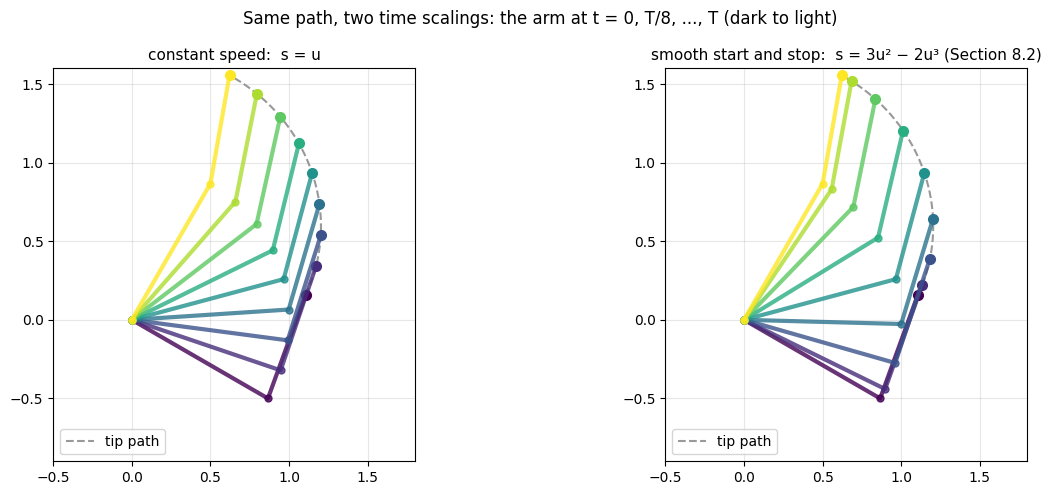

In [3]:
q_a, q_b = np.radians([-30, 100]), np.radians([60, 20])
scalings = [('constant speed:  s = u', lambda u: u),
            ('smooth start and stop:  s = 3u² − 2u³ (Section 8.2)', lambda u: 3 * u**2 - 2 * u**3)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, s_of_u) in zip(axes, scalings):
    u_fine = np.linspace(0, 1, 200)
    tip_path = fk_2R(q_a + np.outer(s_of_u(u_fine), q_b - q_a))[1]
    ax.plot(*tip_path.T, color='0.6', lw=1.5, ls='--', label='tip path')
    for k, u in enumerate(np.linspace(0, 1, 9)):
        q = q_a + s_of_u(u) * (q_b - q_a)
        draw_2R(ax, q, color=plt.cm.viridis(k / 8), alpha=0.8, lw=3)
        ax.plot(*fk_2R(q)[1], 'o', color=plt.cm.viridis(k / 8), ms=7)
    ax.set_title(title, fontsize=11)
    ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.set_xlim(-0.5, 1.8); ax.set_ylim(-0.9, 1.6)
    ax.legend(loc='lower left')
fig.suptitle('Same path, two time scalings: the arm at t = 0, T/8, ..., T (dark to light)', fontsize=12)
plt.tight_layout(); plt.show()

With constant speed the tip advances equal distances in equal times, from the first instant
to the last. The smooth scaling starts gently, covers most of the path in the middle of the
move, and slows down into the goal.

> **Key Takeaways — Section 8.1**
> - Path = geometry, $\boldsymbol\theta(s)$; trajectory = path + timing, $\boldsymbol\theta(s(t))$.
> - On a straight joint-space path, $\dot\theta_i = \Delta_i\dot s$ and $\ddot\theta_i = \Delta_i\ddot s$: all joints share one time scaling and finish together.
> - Scaling law: stretching the time by $k$ divides velocities by $k$ and accelerations by $k^2$.
> - Goals: start and end at rest, continuous velocity (ideally continuous acceleration), within the limits, fast.

## 8.2  Point-to-Point Polynomials

### 8.2.1  Linear interpolation

The simplest time scaling is constant speed, $s(u) = u$:

$$\theta(t) = \theta_0 + \frac{t}{T}\,\Delta, \qquad \dot\theta = \frac{\Delta}{T}, \qquad \ddot\theta = 0 \ \text{ during the move,}$$

where $\Delta = \theta_f - \theta_0$ is the distance the joint travels. (From here on, the formulas are
for one joint, so we drop the index $i$; for the whole arm, apply them to each joint with its own $\Delta_i$.)

It is what a program does when it simply sends evenly spaced goal positions to a servo. Its velocity **jumps** from 0 to $\Delta/T$
at $t = 0$ and back to 0 at $t = T$, so the acceleration is infinite at those two instants.
The motor cannot follow: a position servo falls behind as soon as a linear move starts,
trails behind the command for the whole move, and arrives late and still moving (Section 8.6
models this). Linear interpolation is fine for slow, small moves; for anything quick we
need a velocity that starts and ends at zero.

### 8.2.2  Cubic polynomials

Take one joint. We want it to start at $\theta_0$ with velocity $v_0$ and to reach
$\theta_f$ with velocity $v_f$ at time $T$. Four conditions need four free coefficients, so
we use a cubic:

$$\theta(t) = a_0 + a_1 t + a_2 t^2 + a_3 t^3, \qquad \dot\theta(t) = a_1 + 2a_2 t + 3a_3 t^2,
\qquad \ddot\theta(t) = 2a_2 + 6a_3 t .$$

The four conditions are four linear equations in the coefficients:

$$
\underbrace{\begin{bmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 1 & T & T^2 & T^3 \\ 0 & 1 & 2T & 3T^2 \end{bmatrix}}_{\mathbf{M}}
\begin{bmatrix} a_0 \\ a_1 \\ a_2 \\ a_3 \end{bmatrix}
=
\begin{bmatrix} \theta_0 \\ v_0 \\ \theta_f \\ v_f \end{bmatrix}
\qquad
\begin{aligned}
&\leftarrow \theta(0) = \theta_0 \\ &\leftarrow \dot\theta(0) = v_0 \\ &\leftarrow \theta(T) = \theta_f \\ &\leftarrow \dot\theta(T) = v_f
\end{aligned}
$$

The first two rows give $a_0 = \theta_0$ and $a_1 = v_0$. Substituting them into the last two
rows leaves two equations in $a_2$ and $a_3$, with the solution

$$\boxed{a_2 = \frac{3\Delta - (2v_0 + v_f)\,T}{T^2}, \qquad a_3 = \frac{-2\Delta + (v_0 + v_f)\,T}{T^3}}$$

**Rest to rest** ($v_0 = v_f = 0$): $a_0 = \theta_0$, $a_1 = 0$, $a_2 = 3\Delta/T^2$,
$a_3 = -2\Delta/T^3$. To see the time scaling inside this cubic, substitute the coefficients and
factor out $\Delta$:

$$\theta(t) = \theta_0 + \frac{3\Delta}{T^2}\,t^2 - \frac{2\Delta}{T^3}\,t^3
= \theta_0 + \Delta\left[3\left(\frac{t}{T}\right)^2 - 2\left(\frac{t}{T}\right)^3\right].$$

With the normalized time $u = t/T$ (from 0 at the start to 1 at the end), the bracket depends
on $u$ alone. Comparing with the straight path of Section 8.1, $\theta = \theta_0 + s\,\Delta$, the
bracket **is** the time scaling:

$$s(u) = 3u^2 - 2u^3, \qquad s'(u) = 6u(1 - u), \qquad s''(u) = 6 - 12u ,$$

where $'$ is $d/du$. It satisfies $s(0) = 0$, $s(1) = 1$ and $s'(0) = s'(1) = 0$, and it is the
same for every joint and every move; only $\Delta$ and $T$ change. To get back to time, use the
chain rule with $du/dt = 1/T$ (Section 8.1):

$$\dot\theta = \frac{\Delta}{T}\,s'(u), \qquad \ddot\theta = \frac{\Delta}{T^2}\,s''(u).$$

The velocity is a parabola, zero at both ends, with its peak at the middle:
$\dot\theta_{\max} = 1.5\,\Delta/T$, **50% faster than linear interpolation**, because the cubic
makes up for its slow start and finish. The acceleration falls linearly from $+6\Delta/T^2$ to
$-6\Delta/T^2$: finite everywhere, but it still **jumps** from 0 to $6\Delta/T^2$ at the start
and back to 0 at the end. The velocity is continuous; the acceleration is not.

We keep $v_0$ and $v_f$ in the formulas because Section 8.4 strings cubics together through
waypoints without stopping, which needs nonzero velocities at the joins. The cell codes the
formulas and checks them against solving $\mathbf{M}\mathbf{a} = \mathbf{b}$ numerically.

In [4]:
def cubic_coefficients(q0, qf, T, v0=0.0, vf=0.0):
    # Coefficients [a0, a1, a2, a3] of the cubic with q(0) = q0, q'(0) = v0, q(T) = qf, q'(T) = vf
    a2 = (3 * (qf - q0) - (2 * v0 + vf) * T) / T**2
    a3 = (-2 * (qf - q0) + (v0 + vf) * T) / T**3
    return np.array([q0, v0, a2, a3])


def poly_eval(a, t):
    # Position, velocity and acceleration of the polynomial a[0] + a[1] t + a[2] t^2 + ... (t may be an array)
    t = np.asarray(t, float)
    q   = sum(a[k] * t**k for k in range(len(a)))
    qd  = sum(k * a[k] * t**(k - 1) for k in range(1, len(a)))
    qdd = sum(k * (k - 1) * a[k] * t**(k - 2) for k in range(2, len(a)))
    return q, qd, qdd


q0, qf, T, v0, vf = -30.0, 45.0, 2.0, 10.0, -5.0                   # degrees, seconds
M = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [1, T, T**2, T**3], [0, 1, 2 * T, 3 * T**2]])
print('formulas        :', cubic_coefficients(q0, qf, T, v0, vf))
print('np.linalg.solve :', np.linalg.solve(M, [q0, v0, qf, vf]))

a = cubic_coefficients(0.0, 90.0, 2.0)                             # rest to rest: 90° in 2 s
q, qd, qdd = poly_eval(a, np.linspace(0, 2.0, 2001))
print(f'\nRest to rest, Δ = 90°, T = 2 s: peak velocity {qd.max():.2f}°/s (1.5 Δ/T = {1.5 * 90 / 2:.2f}), '
      f'acceleration at the ends ±{qdd.max():.1f}°/s² (6 Δ/T² = {6 * 90 / 4:.1f})')

formulas        : [-30.    10.    48.75 -17.5 ]
np.linalg.solve : [-30.    10.    48.75 -17.5 ]

Rest to rest, Δ = 90°, T = 2 s: peak velocity 67.50°/s (1.5 Δ/T = 67.50), acceleration at the ends ±135.0°/s² (6 Δ/T² = 135.0)


**Explore the end velocities.** The sliders set $v_0$, $v_f$ and $T$ for a 90° move. With
small end velocities the cubic is an S-curve. Make $v_0$ large and the joint **overshoots**
$\theta_f$ and comes back; make it negative and the joint first moves the wrong way. Large
end velocities in a short time are exactly what makes multi-segment trajectories wander
(Section 8.4).

In [5]:
def explore_cubic():
    def _view(v0=0.0, vf=0.0, T=2.0):
        a = cubic_coefficients(0.0, 90.0, T, v0, vf)
        t = np.linspace(0, T, 400)
        q, qd, qdd = poly_eval(a, t)
        fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
        for ax, y, label in zip(axes, (q, qd, qdd), ('position (°)', 'velocity (°/s)', 'acceleration (°/s²)')):
            ax.plot(t, y, lw=2)
            ax.set_xlabel('t (s)'); ax.set_ylabel(label); ax.grid(alpha=0.3)
        axes[0].axhline(90, color='k', ls=':', lw=1)
        axes[0].set_title(f'cubic from 0° to 90°: max {q.max():.1f}°, min {q.min():.1f}°')
        plt.tight_layout(); plt.show()

    interact(_view,
             v0=FloatSlider(value=0, min=-150, max=150, step=5, description='v₀ (°/s)'),
             vf=FloatSlider(value=0, min=-150, max=150, step=5, description='v_f (°/s)'),
             T=FloatSlider(value=2.0, min=0.5, max=4.0, step=0.1, description='T (s)'))


explore_cubic()

interactive(children=(FloatSlider(value=0.0, description='v₀ (°/s)', max=150.0, min=-150.0, step=5.0), FloatSl…

### 8.2.3  Quintic polynomials

To remove the jump in acceleration we also fix the accelerations at both ends, which makes
six conditions, so we need a quintic (degree 5):

$$\theta(t) = a_0 + a_1 t + a_2 t^2 + a_3 t^3 + a_4 t^4 + a_5 t^5,$$

with $\theta(0) = \theta_0$, $\dot\theta(0) = v_0$, $\ddot\theta(0) = \alpha_0$, and
$\theta(T) = \theta_f$, $\dot\theta(T) = v_f$, $\ddot\theta(T) = \alpha_f$. As before, the
conditions at $t = 0$ give the first coefficients directly ($a_0 = \theta_0$, $a_1 = v_0$,
$a_2 = \alpha_0/2$), and the three conditions at $t = T$ form a $3\times3$ linear system for
$a_3, a_4, a_5$. For rest to rest with zero end accelerations the solution is

$$a_3 = \frac{10\Delta}{T^3},\quad a_4 = -\frac{15\Delta}{T^4},\quad a_5 = \frac{6\Delta}{T^5}
\qquad\Longleftrightarrow\qquad s(u) = 10u^3 - 15u^4 + 6u^5 .$$

Now the velocity **and** the acceleration start and end at zero. The price is a higher peak
speed, $\dot\theta_{\max} = \tfrac{15}{8}\Delta/T = 1.875\,\Delta/T$, at the middle of the move.
The peak acceleration is $\tfrac{10}{\sqrt3}\Delta/T^2 \approx 5.77\,\Delta/T^2$, a little lower
than the cubic's, and it occurs at $u = \tfrac12 \mp \tfrac{\sqrt3}{6}$ instead of at the ends.

The pattern continues: the derivative of acceleration, the **jerk**, now jumps at the ends,
and a degree-7 polynomial with eight conditions makes the jerk start and end at zero too. Each
step makes the start gentler and the middle faster.

The general solution is easiest to compute numerically from the $6\times6$ system:

In [6]:
def quintic_coefficients(q0, qf, T, v0=0.0, vf=0.0, acc0=0.0, accf=0.0):
    # Coefficients [a0, ..., a5] of the quintic with given position, velocity and acceleration at both ends
    M = np.array([[1, 0, 0,     0,        0,         0],
                  [0, 1, 0,     0,        0,         0],
                  [0, 0, 2,     0,        0,         0],
                  [1, T, T**2,  T**3,     T**4,      T**5],
                  [0, 1, 2 * T, 3 * T**2, 4 * T**3,  5 * T**4],
                  [0, 0, 2,     6 * T,    12 * T**2, 20 * T**3]])
    return np.linalg.solve(M, [q0, v0, acc0, qf, vf, accf])


T, D = 2.0, 90.0
print('quintic, rest to rest :', np.round(quintic_coefficients(0.0, D, T), 6))
print('closed form           :', np.round([0, 0, 0, 10 * D / T**3, -15 * D / T**4, 6 * D / T**5], 6))

quintic, rest to rest : [  0.      0.      0.    112.5   -84.375  16.875]
closed form           : [  0.      0.      0.    112.5   -84.375  16.875]


### 8.2.4  Comparing the profiles, and choosing $T$

The plot shows the three rest-to-rest time scalings in normalized form: $s$, $s'$ and $s''$
against $u = t/T$. Multiply the velocity axis by $\Delta/T$ and the acceleration axis by
$\Delta/T^2$ to get a joint's actual values.

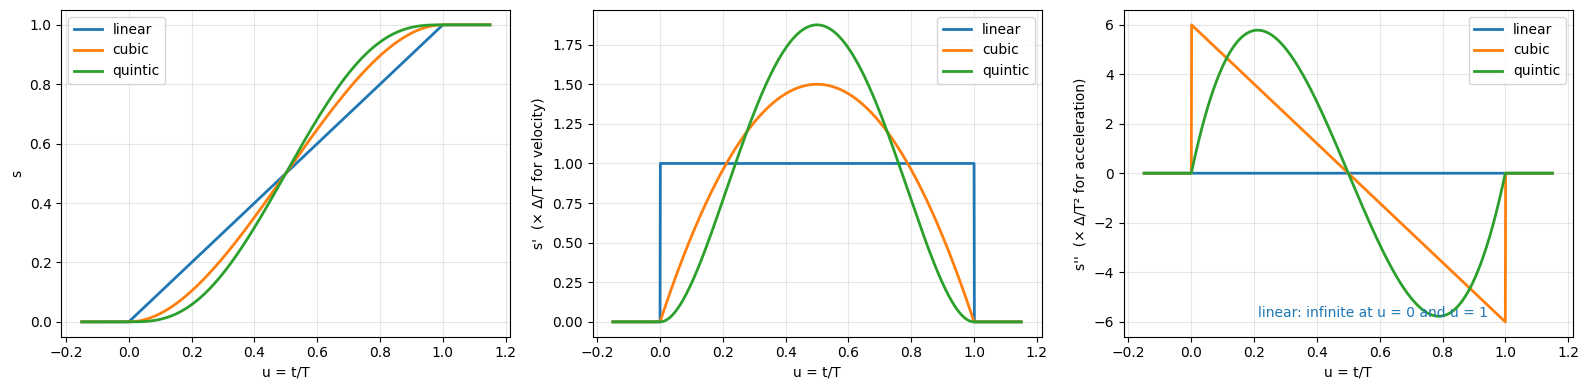

profile     peak velocity   peak acceleration   continuous up to
linear         1.000 Δ/T            infinite   position
cubic          1.500 Δ/T          6.000 Δ/T²   velocity
quintic        1.875 Δ/T          5.773 Δ/T²   acceleration


In [7]:
u = np.linspace(-0.15, 1.15, 1301)
uc = np.clip(u, 0, 1)
moving = (u > 0) & (u < 1)
profiles = {
    'linear':  (uc,                             np.where(moving, 1.0, 0.0),           np.zeros_like(u)),
    'cubic':   (3 * uc**2 - 2 * uc**3,          np.where(moving, 6 * uc * (1 - uc), 0), np.where(moving, 6 - 12 * uc, 0)),
    'quintic': (10 * uc**3 - 15 * uc**4 + 6 * uc**5,
                np.where(moving, 30 * uc**2 * (1 - uc)**2, 0),
                np.where(moving, 60 * uc - 180 * uc**2 + 120 * uc**3, 0)),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, (s, sd, sdd) in profiles.items():
    for ax, y in zip(axes, (s, sd, sdd)):
        ax.plot(u, y, lw=2, label=name)
for ax, label in zip(axes, ("s", "s'  (× Δ/T for velocity)", "s''  (× Δ/T² for acceleration)")):
    ax.set_xlabel('u = t/T'); ax.set_ylabel(label); ax.grid(alpha=0.3); ax.legend()
axes[2].text(0.30, 0.06, 'linear: infinite at u = 0 and u = 1', transform=axes[2].transAxes, color='tab:blue')
plt.tight_layout(); plt.show()

print(f"{'profile':<9} {'peak velocity':>15} {'peak acceleration':>19}   continuous up to")
for name, cont in [('linear', 'position'), ('cubic', 'velocity'), ('quintic', 'acceleration')]:
    s, sd, sdd = profiles[name]
    acc = 'infinite' if name == 'linear' else f'{np.abs(sdd).max():.3f} Δ/T²'
    print(f'{name:<9} {sd.max():10.3f} Δ/T {acc:>19}   {cont}')

**Choosing $T$ from the motor limits.** Suppose a joint may move at most $v_{\max}$ and
accelerate at most $a_{\max}$. A rest-to-rest polynomial with peak values
$c_v\,\Delta/T$ and $c_a\,\Delta/T^2$ stays within both limits if

$$T \ \ge\ T_{\min} = \max\!\left(\frac{c_v\,|\Delta|}{v_{\max}},\ \sqrt{\frac{c_a\,|\Delta|}{a_{\max}}}\right),
\qquad (c_v, c_a) = (1.5,\ 6) \text{ for the cubic},\ (1.875,\ 5.77) \text{ for the quintic}.$$

**Several joints.** All joints share one time scaling (Section 8.1), so the joint that needs
the most time sets $T$ for everyone; the others move more slowly than their limits allow,
and all arrive together.

**Example limits.** For the SO-ARM101 we use $v_{\max} = 180^\circ/\text{s}$ and
$a_{\max} = 720^\circ/\text{s}^2$ for every arm joint throughout this chapter. These are
illustrative values. The real limits depend on the servos, the supply voltage, the load, and
how firmly the gripper holds the block, and are best measured on the robot: the pan joint of
one 12 V SO-ARM101, for example, reached about 200°/s and 2,000°/s². The example move goes
from 6 cm above a pick spot at $(x, y) = (20, -12)$ cm to 6 cm above a place spot at
$(20, 0)$ cm, with the gripper pointing straight down.

In [8]:
V_MAX = np.radians(180.0)            # rad/s   example joint speed limit (every arm joint)
A_MAX = np.radians(720.0)            # rad/s²  example joint acceleration limit
PHI_DOWN = np.radians(-90.0)         # gripper pointing straight down
Z_GRASP, LIFT = 0.015, 0.06          # gripper-point height for grasping a 1-inch block, and lift height (m)
PICK_XY, PLACE_XY = np.array([0.20, -0.12]), np.array([0.20, 0.0])   # pick and place spots (x, y) (m)


def so101_top_down(xy, z):
    # Joint vector (rad) that puts the gripper point at (x, y, z), pointing straight down
    q = so101_ik(np.array([*xy, z]), PHI_DOWN)
    assert q is not None and so101.within_limits(q), f'{xy}, z = {z}: not reachable top-down'
    return q


def poly_min_time(delta, v_max, a_max, cv, ca):
    # Shortest T for a rest-to-rest polynomial with peak velocity cv Δ/T and peak acceleration ca Δ/T²
    return max(cv * np.abs(delta) / v_max, np.sqrt(ca * np.abs(delta) / a_max))


q_start, q_goal = so101_top_down(PICK_XY, Z_GRASP + LIFT), so101_top_down(PLACE_XY, Z_GRASP + LIFT)
delta = q_goal - q_start
print(f"{'joint':<15}{'Δ (°)':>8}{'T_min cubic (s)':>18}{'T_min quintic (s)':>20}")
for name, d in zip(so101.joint_names, delta):
    print(f'{name:<15}{np.degrees(d):8.1f}{poly_min_time(d, V_MAX, A_MAX, 1.5, 6):18.3f}'
          f'{poly_min_time(d, V_MAX, A_MAX, 1.875, 10 / np.sqrt(3)):20.3f}')
T_cubic = max(poly_min_time(d, V_MAX, A_MAX, 1.5, 6) for d in delta)
print(f'\nAll joints together with one cubic: T = {T_cubic:.3f} s, set by shoulder_pan')

joint             Δ (°)   T_min cubic (s)   T_min quintic (s)
shoulder_pan      -36.7             0.553               0.542
shoulder_lift     -20.4             0.412               0.404
elbow_flex         24.0             0.447               0.439
wrist_flex         -3.6             0.174               0.171
wrist_roll          0.0             0.000               0.000

All joints together with one cubic: T = 0.553 s, set by shoulder_pan


`shoulder_pan` has the farthest to go, so it sets $T$; the other joints move only a few
degrees and use a small part of their limits. Its $T_{\min}$ comes from the acceleration
limit, not the speed limit: for moves shorter than $c_a v_{\max}^2 / (c_v^2 a_{\max})$ (120° for
the cubic with these limits) the square root wins.

> **Key Takeaways — Section 8.2**
> - Linear interpolation: constant speed $\Delta/T$, but velocity jumps at both ends (infinite acceleration).
> - Cubic: four conditions $(\theta_0, v_0, \theta_f, v_f)$; $a_2 = [3\Delta - (2v_0 + v_f)T]/T^2$, $a_3 = [-2\Delta + (v_0 + v_f)T]/T^3$. Rest to rest: $s = 3u^2 - 2u^3$, peak velocity $1.5\Delta/T$, acceleration $\pm 6\Delta/T^2$ at the ends (it jumps there).
> - Quintic: six conditions, adds the end accelerations; rest to rest $s = 10u^3 - 15u^4 + 6u^5$, peak velocity $1.875\Delta/T$, acceleration continuous.
> - Choose $T$ from the limits: $T_{\min} = \max(c_v|\Delta|/v_{\max},\ \sqrt{c_a|\Delta|/a_{\max}})$; with several joints the slowest joint sets $T$.

## 8.3  Trapezoidal Velocity Profiles

### 8.3.1  Accelerate, cruise, decelerate

The polynomials of Section 8.2 never use their full speed or acceleration for long: the cubic
reaches its peak speed only for an instant, and its acceleration falls steadily. A
**trapezoidal velocity profile** uses both limits as much as possible. It has three phases:

1. **accelerate** at constant $a$ for a time $t_b = v/a$, until the speed reaches $v$;
2. **cruise** at constant speed $v$;
3. **decelerate** at $-a$ for $t_b$, coming to rest at $\theta_f$.

The velocity is a trapezoid and the position is a parabola, a straight line, and a parabola,
so the profile is also called **linear segment with parabolic blends (LSPB)**. The area under
the velocity is the distance travelled, $\Delta = v\,(T - t_b)$, so

$$T = \frac{|\Delta|}{v} + \frac{v}{a}, \qquad t_b = \frac{v}{a}.$$

During the move (for $\Delta > 0$):

$$
\theta(t) = \begin{cases}
\theta_0 + \tfrac12 a t^2 & 0 \le t < t_b \\
\theta_0 + v\,(t - \tfrac{t_b}{2}) & t_b \le t \le T - t_b \\
\theta_f - \tfrac12 a\,(T - t)^2 & T - t_b < t \le T
\end{cases}
$$

The cruise phase exists only if $2t_b \le T$, that is $v^2 \le a|\Delta|$. A move too short to
reach $v$ becomes a **triangle**: accelerate for half the time, decelerate for the other half,
peak speed $\sqrt{a|\Delta|}$ and $T = 2\sqrt{|\Delta|/a}$.

Sometimes $T$ is given instead (for example, to make one joint finish together with another).
Fix the acceleration $a$ and solve $\Delta = a\,t_b\,(T - t_b)$ for the blend time:

$$t_b = \frac{T - \sqrt{T^2 - 4|\Delta|/a}}{2}, \qquad \text{possible only if } aT^2 \ge 4|\Delta| .$$

<p align="center"><img src="Fig8-02_trapezoid.png" width="900"></p>

<p align="center"><i>Figure 8.2 — Anatomy of a trapezoidal velocity profile. (a) Velocity: accelerate at a for t<sub>b</sub>, cruise at v, decelerate; the area under the curve is the distance Δ. The dashed curve is a cubic with the same Δ and T. (b) Position: parabola, straight line, parabola.</i></p>

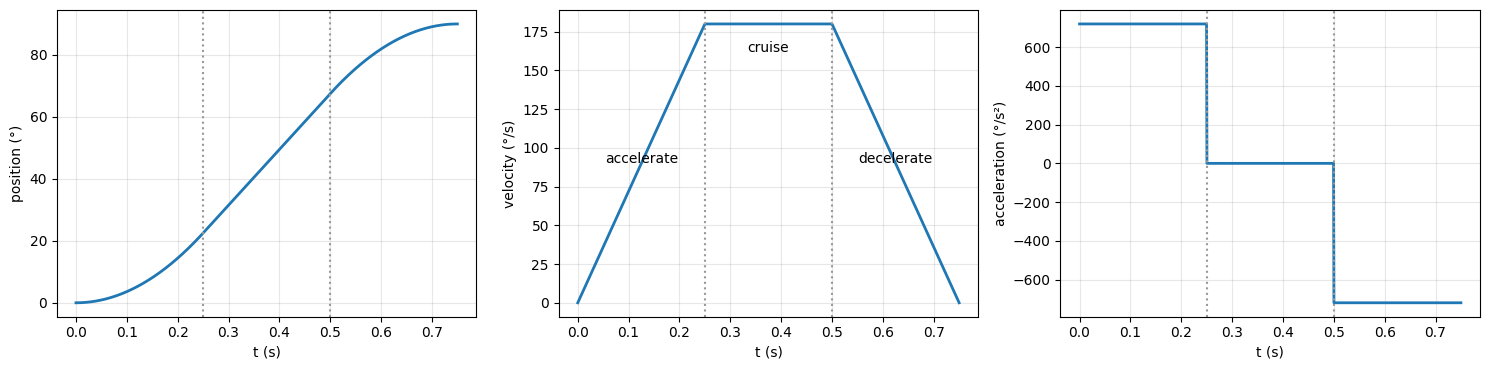

Δ = 90°: T = 0.750 s, cruise at 180°/s, blend time t_b = 0.250 s; check: end position 90.0000°


In [9]:
def trapezoid_min_time(delta, v_max, a_max):
    # Fastest rest-to-rest move of size |delta| with |speed| <= v_max and |acceleration| <= a_max.
    # Returns (T, v, t_b): total time, cruise speed reached, and acceleration (blend) time.
    d = abs(delta)
    v = v_max if d * a_max >= v_max**2 else np.sqrt(d * a_max)    # trapezoid, or triangle if too short
    t_b = v / a_max
    return d / v + t_b, v, t_b


def trapezoid_eval(q0, qf, T, t_b, t):
    # Position, velocity and acceleration at time t (scalar or array) of the trapezoid from q0 to qf
    t = np.clip(np.asarray(t, float), 0, T)
    v = (qf - q0) / (T - t_b)                                      # signed cruise velocity
    a = v / t_b
    accel, decel = t < t_b, t > T - t_b
    q = np.where(accel, q0 + 0.5 * a * t**2, np.where(decel, qf - 0.5 * a * (T - t)**2, q0 + v * (t - t_b / 2)))
    qd = np.where(accel, a * t, np.where(decel, a * (T - t), v))
    qdd = np.where(accel, a, np.where(decel, -a, 0.0))
    return q, qd, qdd


def trapezoid_blend_time(delta, T, a):
    # Blend time of the trapezoid that moves |delta| in exactly T with acceleration a (needs a T² >= 4|delta|)
    disc = T**2 - 4 * abs(delta) / a
    assert disc >= 0, 'T too short for this acceleration'
    return (T - np.sqrt(disc)) / 2


T, v, t_b = trapezoid_min_time(90.0, 180.0, 720.0)              # 90° with 180°/s and 720°/s²
t = np.linspace(0, T, 1001)
q, qd, qdd = trapezoid_eval(0.0, 90.0, T, t_b, t)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, y, label in zip(axes, (q, qd, qdd), ('position (°)', 'velocity (°/s)', 'acceleration (°/s²)')):
    ax.plot(t, y, lw=2)
    for tb_line in (t_b, T - t_b):
        ax.axvline(tb_line, color='0.6', ls=':')
    ax.set_xlabel('t (s)'); ax.set_ylabel(label); ax.grid(alpha=0.3)
axes[1].text(t_b / 2, v * 0.5, 'accelerate', ha='center'); axes[1].text(T / 2, v * 0.9, 'cruise', ha='center')
axes[1].text(T - t_b / 2, v * 0.5, 'decelerate', ha='center')
plt.tight_layout(); plt.show()
print(f'Δ = 90°: T = {T:.3f} s, cruise at {v:.0f}°/s, blend time t_b = {t_b:.3f} s; '
      f'check: end position {q[-1]:.4f}°')

### 8.3.2  The fastest move under speed and acceleration limits

With $v = v_{\max}$ and $a = a_{\max}$ the trapezoid is the **fastest possible** rest-to-rest
move within the two limits. The reason: to cover $\Delta$ as quickly as possible the joint must
be as fast as possible at every instant. It cannot speed up faster than $a_{\max}$, cannot
cruise faster than $v_{\max}$, and must still be able to stop in time, which it does only by
braking at $a_{\max}$ at the last possible moment. The trapezoid does exactly that. This
"full acceleration, full speed, full braking" structure is called **bang-coast-bang**.

The cell compares the shortest time of each profile for several move sizes, with the example
limits of Section 8.2.4.

Shortest rest-to-rest time (s) with v_max = 180°/s, a_max = 720°/s²

 Δ (°)  trapezoid    cubic  quintic   trapezoid saves
    10      0.236    0.289    0.283    18.4% vs cubic
    20      0.333    0.408    0.400    18.4% vs cubic
    45      0.500    0.612    0.601    18.4% vs cubic
    90      0.750    0.866    0.938    13.4% vs cubic
   180      1.250    1.500    1.875    16.7% vs cubic


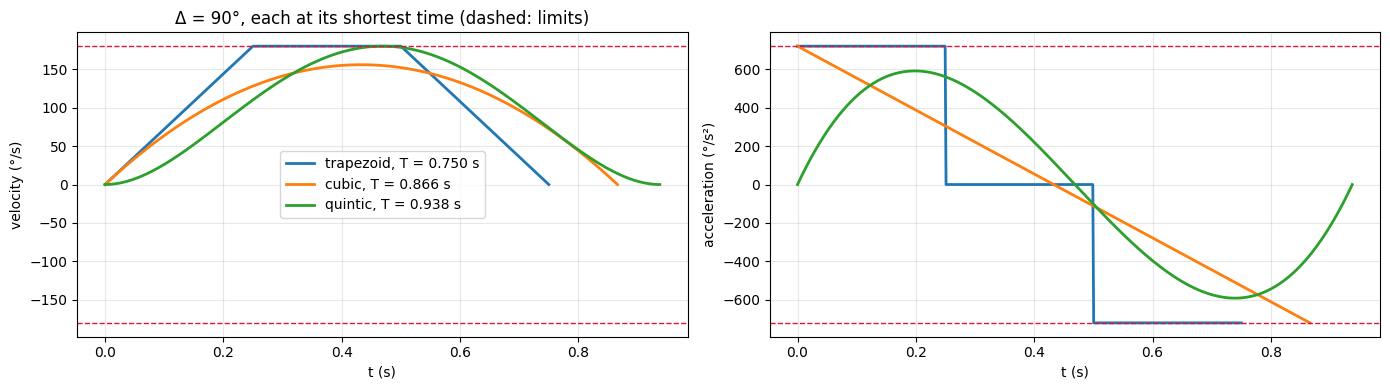

In [10]:
v_lim, a_lim = 180.0, 720.0                                      # °/s, °/s²
print(f'Shortest rest-to-rest time (s) with v_max = {v_lim:.0f}°/s, a_max = {a_lim:.0f}°/s²\n')
print(f"{'Δ (°)':>6} {'trapezoid':>10} {'cubic':>8} {'quintic':>8}   trapezoid saves")
for D in (10, 20, 45, 90, 180):
    T_trap = trapezoid_min_time(D, v_lim, a_lim)[0]
    T_cub = poly_min_time(D, v_lim, a_lim, 1.5, 6)
    T_qui = poly_min_time(D, v_lim, a_lim, 1.875, 10 / np.sqrt(3))
    print(f'{D:6d} {T_trap:10.3f} {T_cub:8.3f} {T_qui:8.3f}   {100 * (1 - T_trap / T_cub):5.1f}% vs cubic')

D = 90.0
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
T_trap, _, t_b = trapezoid_min_time(D, v_lim, a_lim)
t = np.linspace(0, T_trap, 500)
_, qd, qdd = trapezoid_eval(0, D, T_trap, t_b, t)
axes[0].plot(t, qd, lw=2, label=f'trapezoid, T = {T_trap:.3f} s'); axes[1].plot(t, qdd, lw=2)
for name, cv, ca in [('cubic', 1.5, 6), ('quintic', 1.875, 10 / np.sqrt(3))]:
    Tp = poly_min_time(D, v_lim, a_lim, cv, ca)
    coeffs = cubic_coefficients(0, D, Tp) if name == 'cubic' else quintic_coefficients(0, D, Tp)
    t = np.linspace(0, Tp, 500)
    _, qd, qdd = poly_eval(coeffs, t)
    axes[0].plot(t, qd, lw=2, label=f'{name}, T = {Tp:.3f} s'); axes[1].plot(t, qdd, lw=2)
for ax, lim, label in [(axes[0], v_lim, 'velocity (°/s)'), (axes[1], a_lim, 'acceleration (°/s²)')]:
    ax.axhline(lim, color='crimson', ls='--', lw=1); ax.axhline(-lim, color='crimson', ls='--', lw=1)
    ax.set_xlabel('t (s)'); ax.set_ylabel(label); ax.grid(alpha=0.3)
axes[0].legend(); axes[0].set_title(f'Δ = {D:.0f}°, each at its shortest time (dashed: limits)')
plt.tight_layout(); plt.show()

The trapezoid is 13% to 18% faster than the cubic over this range, and more than that
against the quintic for long moves: it rides along both limits, while the polynomials touch
each limit only at one instant.

**Smoothness.** The trapezoid's acceleration jumps four times (at the start and end of each
blend), so like the cubic it has continuous velocity but not continuous acceleration.
Industrial drives often use an **S-curve** profile, which also limits the jerk by ramping the
acceleration up and down linearly; it is a trapezoid of *acceleration* inside a smooth
velocity profile.

> **Servos do this too.** Sent a single goal angle, a smart servo such as the STS3215 of the
> SO-ARM101 runs its own trapezoidal velocity profile toward the goal. Section 8.6 discusses how
> that built-in profile interacts with the trajectories of this chapter.

### 8.3.3  Synchronizing several joints

If each joint ran its own fastest trapezoid, the joints would finish at different times and
the arm would not follow the straight joint-space path. Instead, give all joints **one**
trapezoidal time scaling $s(t)$. Since $\dot\theta_i = \Delta_i\,\dot s$ and
$\ddot\theta_i = \Delta_i\,\ddot s$, every joint stays within its limits if

$$\dot s \le \dot s_{\max} = \min_i \frac{v_{\max,i}}{|\Delta_i|}, \qquad
\ddot s \le \ddot s_{\max} = \min_i \frac{a_{\max,i}}{|\Delta_i|},$$

and the fastest such $s(t)$ is the trapezoid from 0 to 1 with limits $\dot s_{\max}$ and
$\ddot s_{\max}$. The joint with the largest $|\Delta_i|$ (relative to its limits) uses its full
speed and acceleration; the others scale down in proportion.

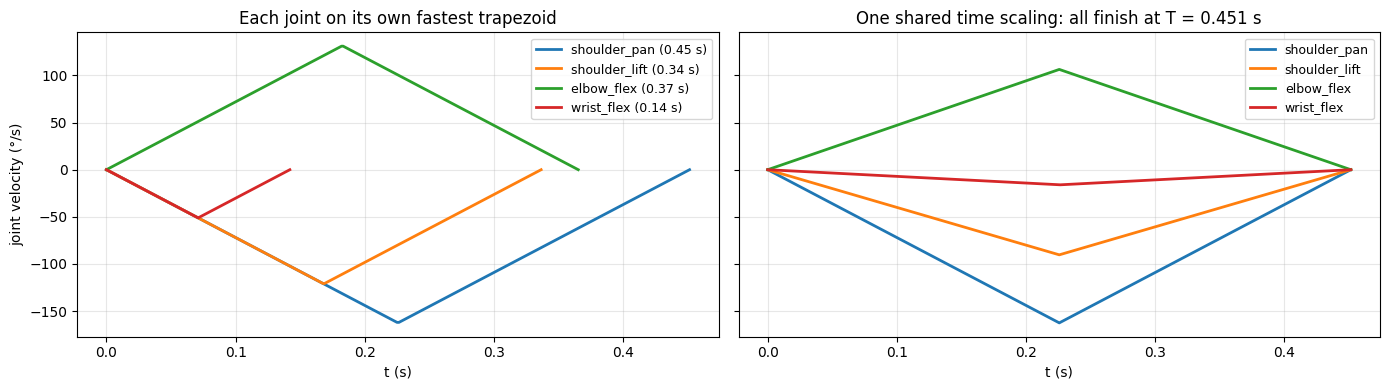

Synchronized trapezoid: T = 0.451 s   (one cubic within the same limits: 0.553 s)


In [11]:
def sync_trapezoid(q0, qf, v_max, a_max):
    # One trapezoidal time scaling for all joints, as fast as the limits allow.
    # v_max, a_max: scalars or one value per joint. Returns (T, traj) with traj(t) -> (q, qd, qdd).
    q0, qf = np.asarray(q0, float), np.asarray(qf, float)
    d = np.abs(qf - q0)
    moving = d > 1e-12
    sd_max = np.min(np.broadcast_to(v_max, d.shape)[moving] / d[moving])
    sdd_max = np.min(np.broadcast_to(a_max, d.shape)[moving] / d[moving])
    T, _, t_b = trapezoid_min_time(1.0, sd_max, sdd_max)

    def traj(t):
        s, sd, sdd = trapezoid_eval(0.0, 1.0, T, t_b, t)
        return q0 + s * (qf - q0), sd * (qf - q0), sdd * (qf - q0)
    return T, traj


def sample(traj, T, n=601):
    # Sample traj(t) -> (q, qd, qdd) at n times from 0 to T; returns t and three (n, dof) arrays
    t = np.linspace(0, T, n)
    q, qd, qdd = (np.array(x) for x in zip(*(traj(ti) for ti in t)))
    return t, q, qd, qdd


T_sync, traj_sync = sync_trapezoid(q_start, q_goal, V_MAX, A_MAX)
t, q, qd, qdd = sample(traj_sync, T_sync)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for i, name in enumerate(so101.joint_names[:4]):
    Ti, _, tbi = trapezoid_min_time(delta[i], V_MAX, A_MAX)
    ti = np.linspace(0, Ti, 300)
    axes[0].plot(ti, np.degrees(trapezoid_eval(q_start[i], q_goal[i], Ti, tbi, ti)[1]), lw=2, label=f'{name} ({Ti:.2f} s)')
    axes[1].plot(t, np.degrees(qd[:, i]), lw=2, label=name)
axes[0].set_title('Each joint on its own fastest trapezoid'); axes[1].set_title(f'One shared time scaling: all finish at T = {T_sync:.3f} s')
for ax in axes:
    ax.set_xlabel('t (s)'); ax.grid(alpha=0.3); ax.legend(fontsize=9)
axes[0].set_ylabel('joint velocity (°/s)')
plt.tight_layout(); plt.show()
print(f'Synchronized trapezoid: T = {T_sync:.3f} s   (one cubic within the same limits: {T_cubic:.3f} s)')

On the left, the joints finish at different times, so the arm leaves the straight
joint-space path between the two poses; the gripper's pitch, $-(\theta_2 + \theta_3 + \theta_4)$,
changes during the move because the three joints no longer move in step. On the right, every
joint follows the same profile shape, scaled by its distance, and they all arrive together,
in the time the pan joint needs anyway.

| Profile | $s(u)$ | Peak velocity | Peak acceleration | Continuous up to | Use |
|---|---|---|---|---|---|
| Linear | $u$ | $\Delta/T$ | infinite (ends) | position | slow moves only |
| Cubic | $3u^2 - 2u^3$ | $1.5\,\Delta/T$ | $6\,\Delta/T^2$ (ends) | velocity | simple and smooth; also passes through points with given velocities (Section 8.4) |
| Quintic | $10u^3 - 15u^4 + 6u^5$ | $1.875\,\Delta/T$ | $5.77\,\Delta/T^2$ | acceleration | gentlest start and stop |
| Trapezoid | accelerate, cruise, decelerate | $v$ (e.g. $v_{\max}$) | $a$ (e.g. $a_{\max}$) | velocity | fastest within $v_{\max}$, $a_{\max}$ |

> **Key Takeaways — Section 8.3**
> - Trapezoid (LSPB): accelerate at $a$ for $t_b = v/a$, cruise at $v$, decelerate; $T = |\Delta|/v + v/a$; a triangle if $v^2 > a|\Delta|$.
> - With $v = v_{\max}$ and $a = a_{\max}$ it is the fastest rest-to-rest move within the limits (bang-coast-bang), about 15% faster than the cubic.
> - For a given $T$: $t_b = \big(T - \sqrt{T^2 - 4|\Delta|/a}\big)/2$.
> - Synchronize joints with one time scaling: $\dot s_{\max} = \min_i v_{\max,i}/|\Delta_i|$, $\ddot s_{\max} = \min_i a_{\max,i}/|\Delta_i|$.

## 8.4  Via Points: Moving Through Waypoints Without Stopping

A pick and place visits a sequence of waypoints: above the block, down to the block (close
the gripper), back up, over to above the goal, down (open the gripper), and up again. With a
rest-to-rest move between each pair, the arm **stops at every waypoint**, and every stop
costs time: the arm must slow down to zero and speed up again.

Only some waypoints need a stop. At the block and at the goal the arm must be at rest while
the gripper closes or opens. The points *above* them are there to shape the path, so that the
block is lifted clear of the table and lowered from above; the arm only needs to pass through
or near them. These are **via points**. This section gives two ways to pass via points
without stopping:

- **Cubic segments** with nonzero velocities at the via points (Section 8.4.1): the trajectory
  passes *exactly* through every point.
- **Linear segments with parabolic blends** (Section 8.4.2): the trapezoid of Section 8.3,
  extended to many points; the trajectory passes *near* the via points and rounds the corners.

<p align="center"><img src="Fig8-03_via_points.png" width="900"></p>

<p align="center"><i>Figure 8.3 — Two ways through via points. (a) Cubic segments with a velocity v<sub>k</sub> at each via point pass exactly through every point; a joint that turns back gets v = 0. (b) Linear segments with parabolic blends (shaded) start and stop exactly at the end points but miss each via point by δ = (V<sub>k</sub> − V<sub>k−1</sub>) t<sub>b</sub>/8.</i></p>

### 8.4.1  Cubic segments with velocities at the via points

Let the waypoints be $\theta_0, \theta_1, \dots, \theta_n$ for one joint: the start, $n - 1$ via
points, and the goal. Segment $k$ ($k = 0, \dots, n-1$) runs from $\theta_k$ to $\theta_{k+1}$ in
time $T_k$, with $\Delta_k = \theta_{k+1} - \theta_k$, and each segment is a cubic of Section 8.2.2.

**Count the unknowns and the conditions.** $n$ cubic segments have $4n$ coefficients. The
conditions we certainly want are:

| Condition | Equations |
|---|---|
| each segment starts at $\theta_k$ and ends at $\theta_{k+1}$ | $2n$ |
| the joint starts and ends at rest | $2$ |
| the velocity is continuous at each via point | $n - 1$ |
| **total** | $3n + 1$ |

That leaves $4n - (3n + 1) = n - 1$ conditions to choose: **one per via point**. A convenient way
to see them is to name the velocity at each waypoint, $v_0, v_1, \dots, v_n$, and build segment $k$
as the cubic from $(\theta_k, v_k)$ to $(\theta_{k+1}, v_{k+1})$ with the formulas of Section 8.2.2.
Then the first $3n + 1$ conditions hold automatically: each segment hits its two waypoints,
$v_0 = v_n = 0$ gives the rest conditions, and neighbouring segments share $v_k$, so the velocity
is continuous. **The only unknowns left are the $n - 1$ via velocities $v_1, \dots, v_{n-1}$**, and
we need $n - 1$ equations for them. The two rules below supply those equations in different ways.

**Rule 1: average the slopes (one explicit formula per via point).** Let $m_k = \Delta_k / T_k$ be
the average speed of segment $k$. At via point $k$,

$$v_k = \begin{cases} \tfrac12\,(m_{k-1} + m_k) & \text{if } m_{k-1} \text{ and } m_k \text{ have the same sign,} \\ 0 & \text{otherwise.} \end{cases}$$

This gives the $n - 1$ equations directly, each via velocity on its own, so nothing has to be
solved. A joint that keeps moving the same way passes through at about its average speed; a joint
that turns back stops at its turning point. Nothing in
it asks for continuous acceleration, so the acceleration jumps at the via points.

**Rule 2: continuous acceleration (the cubic spline).** Use the $n - 1$ free conditions to make the
acceleration continuous at every via point. From the coefficients of Section 8.2.2, a cubic segment
with end velocities $v_0, v_f$ has the accelerations

$$\ddot\theta(0) = \frac{6\Delta - (4v_0 + 2v_f)\,T}{T^2}, \qquad \ddot\theta(T) = \frac{-6\Delta + (2v_0 + 4v_f)\,T}{T^2}$$

at its two ends. (They follow from $\ddot\theta(t) = 2a_2 + 6a_3 t$: $\ddot\theta(0) = 2a_2$ and
$\ddot\theta(T) = 2a_2 + 6a_3T$, with $a_2$, $a_3$ from Section 8.2.2.)

At via point $k$, two segments meet. The segment **arriving** is segment $k-1$: it has $\Delta_{k-1}$
and $T_{k-1}$, starts with $v_{k-1}$ and ends with $v_k$. The segment **leaving** is segment $k$: it has
$\Delta_k$ and $T_k$, starts with $v_k$ and ends with $v_{k+1}$. Their accelerations at the via point are

$$\ddot\theta_{k-1}(T_{k-1}) = \frac{-6\Delta_{k-1} + (2v_{k-1} + 4v_k)\,T_{k-1}}{T_{k-1}^2}, \qquad
\ddot\theta_k(0) = \frac{6\Delta_k - (4v_k + 2v_{k+1})\,T_k}{T_k^2}.$$

Set them equal and split each fraction:

$$-\frac{6\Delta_{k-1}}{T_{k-1}^2} + \frac{2v_{k-1} + 4v_k}{T_{k-1}} = \frac{6\Delta_k}{T_k^2} - \frac{4v_k + 2v_{k+1}}{T_k}.$$

Move the velocities to the left and the $\Delta$ terms to the right:

$$\frac{2v_{k-1}}{T_{k-1}} + \frac{4v_k}{T_{k-1}} + \frac{4v_k}{T_k} + \frac{2v_{k+1}}{T_k} = \frac{6\Delta_{k-1}}{T_{k-1}^2} + \frac{6\Delta_k}{T_k^2}.$$

Divide by 2 and group the two $v_k$ terms. This gives one equation at each via point $k = 1, \dots, n-1$:

$$\boxed{\frac{v_{k-1}}{T_{k-1}} + 2\left(\frac{1}{T_{k-1}} + \frac{1}{T_k}\right) v_k + \frac{v_{k+1}}{T_k}
= 3\left(\frac{\Delta_{k-1}}{T_{k-1}^2} + \frac{\Delta_k}{T_k^2}\right)}$$

That is $n - 1$ linear equations for the $n - 1$ unknowns $v_1, \dots, v_{n-1}$ ($v_0 = v_n = 0$ are
known), so the count closes: $4n$ conditions for $4n$ coefficients, and the solution is unique.
Unlike Rule 1, the via velocities are **coupled**: each equation involves a via velocity and its two
neighbours, so they must be solved together. The matrix is **tridiagonal**. For the five waypoints
used below ($n = 4$ segments, 16 coefficients, 3 via points):

$$
\begin{bmatrix}
2\left(\frac{1}{T_0} + \frac{1}{T_1}\right) & \frac{1}{T_1} & 0 \\
\frac{1}{T_1} & 2\left(\frac{1}{T_1} + \frac{1}{T_2}\right) & \frac{1}{T_2} \\
0 & \frac{1}{T_2} & 2\left(\frac{1}{T_2} + \frac{1}{T_3}\right)
\end{bmatrix}
\begin{bmatrix} v_1 \\ v_2 \\ v_3 \end{bmatrix}
=
3\begin{bmatrix}
\Delta_0/T_0^2 + \Delta_1/T_1^2 \\
\Delta_1/T_1^2 + \Delta_2/T_2^2 \\
\Delta_2/T_2^2 + \Delta_3/T_3^2
\end{bmatrix}
$$

(the terms with $v_0$ and $v_4$ drop out because both are zero). The solution is the **cubic
spline** through the waypoints. Among all trajectories that pass through the waypoints at the given
times and start and end at rest, the spline has the smallest $\int \ddot\theta^2\,dt$: in that sense
it is the smoothest.

| | Unknowns | Equations | How they are found |
|---|---|---|---|
| Stop at every point | none | — | $v_1 = \dots = v_{n-1} = 0$ |
| Rule 1: average slopes | $n - 1$ via velocities | $n - 1$, one per via point | each computed on its own |
| Rule 2: cubic spline | $n - 1$ via velocities | $n - 1$, one per via point | one tridiagonal linear system |

The cell compares stopping at every waypoint, Rule 1 and Rule 2 for one joint and five
waypoints.

method                   via velocities (°/s)          peak speed  peak accel.  largest accel. jump
stop at every point      [0. 0. 0.]                        60.0°/s     240.0°/s²             400.0°/s²
Rule 1: average slopes   [40.  0.  0.]                     60.0°/s     239.8°/s²             146.2°/s²
Rule 2: cubic spline     [ 64.3 -21.4 -11.5]               65.8°/s     151.1°/s²               0.0°/s²


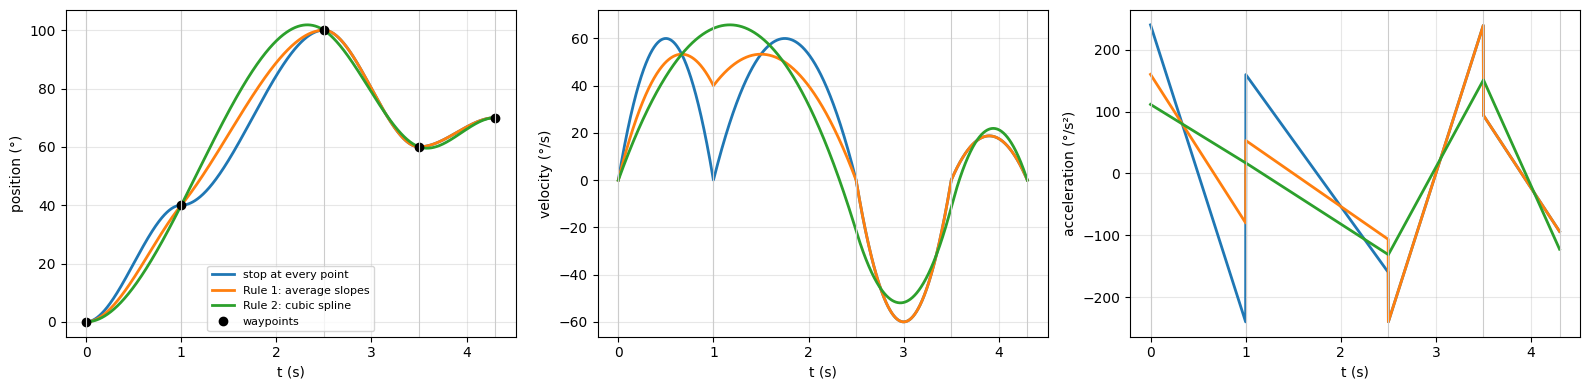

In [12]:
def cubic_segments(points, durations, velocities):
    # Piecewise cubic through waypoints (n+1, dof) with segment durations (n,) and waypoint velocities (n+1, dof).
    # Returns (traj, T) with traj(t) -> (q, qd, qdd).
    P, V, Tk = np.atleast_2d(points).astype(float), np.atleast_2d(velocities).astype(float), np.asarray(durations, float)
    t_knots = np.r_[0.0, np.cumsum(Tk)]
    coeffs = [[cubic_coefficients(P[k, j], P[k + 1, j], Tk[k], V[k, j], V[k + 1, j]) for j in range(P.shape[1])]
              for k in range(len(Tk))]

    def traj(t):
        t = min(max(t, 0.0), t_knots[-1])
        k = min(np.searchsorted(t_knots, t, side='right') - 1, len(Tk) - 1)
        return tuple(np.array(x) for x in zip(*(poly_eval(a, t - t_knots[k]) for a in coeffs[k])))
    return traj, t_knots[-1]


def via_velocities_average(points, durations):
    # Rule 1: average of the neighbouring slopes if they have the same sign, else 0; rest at both ends
    P, Tk = np.atleast_2d(points).astype(float), np.asarray(durations, float)
    m = np.diff(P, axis=0) / Tk[:, None]                                  # average speed of each segment
    V = np.zeros_like(P)
    V[1:-1] = np.where(np.sign(m[:-1]) == np.sign(m[1:]), 0.5 * (m[:-1] + m[1:]), 0.0)
    return V


def via_velocities_spline(points, durations):
    # Rule 2: velocities that make the acceleration continuous (clamped cubic spline); rest at both ends
    P, Tk = np.atleast_2d(points).astype(float), np.asarray(durations, float)
    n, D = len(Tk), np.diff(P, axis=0)
    A, B = np.zeros((n - 1, n - 1)), np.zeros((n - 1, P.shape[1]))
    for i, k in enumerate(range(1, n)):                                  # one equation per via point k
        A[i, i] = 2 * (1 / Tk[k - 1] + 1 / Tk[k])
        if i > 0:
            A[i, i - 1] = 1 / Tk[k - 1]
        if i < n - 2:
            A[i, i + 1] = 1 / Tk[k]
        B[i] = 3 * (D[k - 1] / Tk[k - 1]**2 + D[k] / Tk[k]**2)
    V = np.zeros_like(P)
    V[1:-1] = np.linalg.solve(A, B)
    return V


wp = np.array([[0.0], [40.0], [100.0], [60.0], [70.0]])                  # one joint, degrees
durs = np.array([1.0, 1.5, 1.0, 0.8])                                    # seconds
methods_1d = {'stop at every point': np.zeros_like(wp),
              'Rule 1: average slopes': via_velocities_average(wp, durs),
              'Rule 2: cubic spline': via_velocities_spline(wp, durs)}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
t_knots = np.r_[0, np.cumsum(durs)]
print(f"{'method':<24} {'via velocities (°/s)':<28} {'peak speed':>11} {'peak accel.':>12} {'largest accel. jump':>20}")
for name, V in methods_1d.items():
    traj, T = cubic_segments(wp, durs, V)
    t, q, qd, qdd = sample(traj, T, 2001)
    for ax, y in zip(axes, (q, qd, qdd)):
        ax.plot(t, y[:, 0], lw=2, label=name)
    jump = max(abs(traj(tk - 1e-9)[2] - traj(tk + 1e-9)[2]).max() for tk in t_knots[1:-1])
    print(f'{name:<24} {np.array2string(V[1:-1, 0], precision=1):<28} {np.abs(qd).max():9.1f}°/s '
          f'{np.abs(qdd).max():9.1f}°/s² {jump:17.1f}°/s²')
axes[0].plot(t_knots, wp[:, 0], 'ko', ms=6, label='waypoints')
for ax, label in zip(axes, ('position (°)', 'velocity (°/s)', 'acceleration (°/s²)')):
    ax.set_xlabel('t (s)'); ax.set_ylabel(label); ax.grid(alpha=0.3)
    for tk in t_knots:
        ax.axvline(tk, color='0.8', lw=0.8)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Stopping at every point brings the velocity to zero at each via point. Rule 1 keeps moving
through 40°, where the joint continues upward, and stops at 100° and at 60°, where it turns
back. The spline keeps the acceleration continuous (no jumps at the vertical lines) and has
by far the lowest peak acceleration, but it runs through every via point with some velocity,
even where the joint turns back, so it overshoots: it climbs past 100° before coming down,
and dips below 60° before rising to 70°. We will see what that means in space shortly.

### 8.4.2  Linear segments with parabolic blends

The trapezoid of Section 8.3 is a straight line in time with a parabola at each end. With
more waypoints, keep that idea: move along each segment at **constant velocity**
$V_k = \Delta_k / T_k$, and around each waypoint replace the corner between two segments by a
**parabolic blend**, a period $t_{b,k}$ of constant acceleration $(V_k - V_{k-1})/t_{b,k}$
centred on the waypoint time. At the first and last waypoints the velocity before (after) the
motion is zero, so those blends are exactly the accelerate and decelerate phases of a trapezoid.

The trajectory starts exactly at $\theta_0$ and stops exactly at $\theta_n$, but it does **not**
pass through the via points. In the middle of blend $k$ it is off by

$$\delta_k = \frac{(V_k - V_{k-1})\,t_{b,k}}{8},$$

because during the half-blend before the waypoint it is still on the incoming line but has
started to turn. With the shortest blend the acceleration limit allows,
$t_{b,k} = |V_k - V_{k-1}|/a_{\max}$, the miss is $\delta_k = (V_k - V_{k-1})^2/(8a_{\max})$: a fast
change of direction with a low acceleration limit cuts the corner the most.

**Planning from the limits.** For several joints:

1. Cruise as fast as the slowest joint allows: $T_k = \max_i |\Delta_{k,i}| / v_{\max,i}$.
2. Blend as quickly as the slowest joint allows, with **one** blend time per waypoint for all
   joints: $t_{b,k} = \max_i |V_{k,i} - V_{k-1,i}| / a_{\max,i}$. Because all joints blend
   together, the corner of the joint-space path is replaced by one smooth curve.
3. The two blends of a segment must not overlap, $(t_{b,k} + t_{b,k+1})/2 \le T_k$. If they do, the
   segment is too short to reach its cruise speed: lengthen $T_k$ (which lowers $V_k$ and shortens
   the blends) until they fit.

The total time is $\sum_k T_k + (t_{b,0} + t_{b,n})/2$. Industrial robot languages offer the same
choice for every waypoint: an exact stop, or a "fly-by" point that the robot only passes
near (ABB calls the allowed distance a *zone*, KUKA *approximate positioning*, Universal Robots
a *blend radius*).

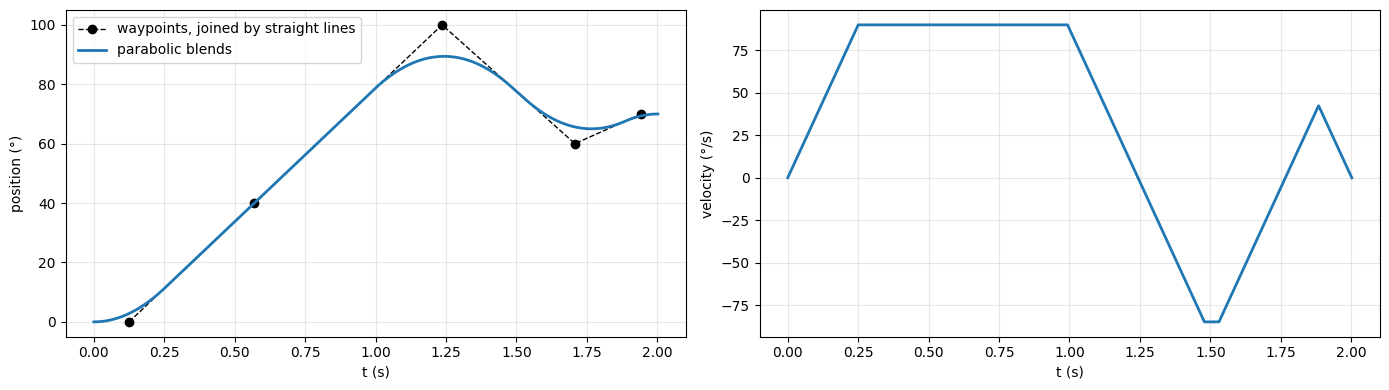

Total time 2.002 s, peak speed 90.0°/s, peak acceleration 360.0°/s²

via point  θ_k (°)  at the blend centre (°)    miss   (V_k - V_k-1) t_b / 8
        1     40.0                    40.00    0.00                    0.00
        2    100.0                    89.39  -10.61                  -10.61
        3     60.0                    65.62    5.62                    5.62


In [13]:
def parabolic_blends(points, durations, blend_times):
    # Linear segments with parabolic blends through waypoints (n+1, dof); segment durations (n,);
    # blend times (n+1,), one per waypoint, the first and last being the start and stop.
    # Returns (traj, T) with traj(t) -> (q, qd, qdd); the motion starts at t = 0.
    P, Tk, tb = np.atleast_2d(points).astype(float), np.asarray(durations, float), np.asarray(blend_times, float)
    n, zero = len(Tk), np.zeros(P.shape[1])
    t_knots = np.r_[0.0, np.cumsum(Tk)]                                   # waypoint times
    V = np.vstack([zero, np.diff(P, axis=0) / Tk[:, None], zero])         # V[k]: velocity before waypoint k, V[k+1]: after
    dV = V[1:] - V[:-1]
    acc = np.divide(dV, tb[:, None], out=np.zeros_like(dV), where=tb[:, None] > 0)   # constant acceleration in blend k
                                                                          # (no blend where the velocity does not change)
    assert np.all((tb[:-1] + tb[1:]) / 2 <= Tk + 1e-9), 'blends overlap: lengthen the segments'
    t_start, t_end = -tb[0] / 2, t_knots[-1] + tb[-1] / 2                 # the first blend starts before waypoint 0

    def traj(t):
        t = t + t_start
        if t <= t_start:                                                  # before the start: at rest at the first point
            return P[0].copy(), zero, zero
        if t >= t_end:                                                    # after the end: at rest at the last point
            return P[-1].copy(), zero, zero
        for k in range(n + 1):
            if abs(t - t_knots[k]) <= tb[k] / 2:                         # inside blend k
                tau = t - (t_knots[k] - tb[k] / 2)
                return P[k] - V[k] * tb[k] / 2 + V[k] * tau + 0.5 * acc[k] * tau**2, V[k] + acc[k] * tau, acc[k]
        k = min(max(np.searchsorted(t_knots, t, side='right') - 1, 0), n - 1)
        return P[k] + V[k + 1] * (t - t_knots[k]), V[k + 1], zero          # on the straight part of segment k
    return traj, t_end - t_start


def plan_blends(points, v_max, a_max):
    # Segment durations and blend times from the speed and acceleration limits (steps 1 to 3 above)
    P = np.atleast_2d(points).astype(float)
    zero = np.zeros((1, P.shape[1]))
    Tk = np.max(np.abs(np.diff(P, axis=0)) / v_max, axis=1)              # 1. cruise at the speed limit
    for _ in range(100):
        V = np.vstack([zero, np.diff(P, axis=0) / Tk[:, None], zero])
        tb = np.max(np.abs(np.diff(V, axis=0)) / a_max, axis=1)           # 2. shortest common blend
        need = (tb[:-1] + tb[1:]) / 2
        if np.all(Tk >= need * (1 - 1e-9)):
            break
        Tk = np.where(need > Tk, np.sqrt(Tk * need) * 1.0001, Tk)         # 3. lengthen segments whose blends overlap
    return Tk, tb


Tk, tb = plan_blends(wp, 90.0, 360.0)                                    # the five waypoints above: 90°/s, 360°/s²
traj, T = parabolic_blends(wp, Tk, tb)
t, q, qd, qdd = sample(traj, T, 3001)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
t_wp = np.r_[0, np.cumsum(Tk)] + tb[0] / 2                               # waypoint times on the new clock
axes[0].plot(t_wp, wp[:, 0], 'k--o', lw=1, ms=6, label='waypoints, joined by straight lines')
axes[0].plot(t, q[:, 0], lw=2, label='parabolic blends')
axes[1].plot(t, qd[:, 0], lw=2)
for ax, label in zip(axes, ('position (°)', 'velocity (°/s)')):
    ax.set_xlabel('t (s)'); ax.set_ylabel(label); ax.grid(alpha=0.3)
axes[0].legend(); plt.tight_layout(); plt.show()

V = np.vstack([[0.0], np.diff(wp, axis=0) / Tk[:, None], [0.0]])
print(f'Total time {T:.3f} s, peak speed {np.abs(qd).max():.1f}°/s, peak acceleration {np.abs(qdd).max():.1f}°/s²')
print(f"\n{'via point':>9} {'θ_k (°)':>8} {'at the blend centre (°)':>24} {'miss':>7} {'(V_k - V_k-1) t_b / 8':>23}")
for k in range(1, len(wp) - 1):
    reached = traj(t_wp[k])[0][0]
    print(f'{k:9d} {wp[k, 0]:8.1f} {reached:24.2f} {reached - wp[k, 0]:7.2f} {(V[k + 1, 0] - V[k, 0]) * tb[k] / 8:23.2f}')

The dashed polyline is the constant-velocity reference: each waypoint is drawn at its waypoint
time, $t_k$, shifted by half the first blend so the motion starts at $t = 0$. The trajectory
starts exactly at the first point and stops exactly at the last one; its first and last blends
are the trapezoid's acceleration and deceleration. In between it cruises at the 90°/s limit on
the long segments and rounds every corner with a 360°/s² blend. Via point 1 is not a corner at all (both neighbouring segments run at the speed
limit, upward), so it is passed exactly. At the other via points the miss is exactly
$(V_k - V_{k-1})t_{b,k}/8$: at the 100° peak the joint turns around more than 10° early, the
price of not stopping there.

### 8.4.3  Comparing the methods on a 2R arm

Now the shape in space. The planar 2R arm works in a vertical plane, with its base at the
origin and a table at $y = 0.05$ m. It must take a block from $A = (1.35, 0.1)$ to
$B = (0.55, 0.1)$, lifting it through the via points $A' = (1.35, 0.7)$ above $A$ and
$B' = (0.55, 0.7)$ above $B$. The waypoints are converted to joint angles with `ik_2R` on the
elbow-up branch (`elbow=-1`), which keeps the elbow well above the table, and each method
interpolates the *joint angles*. The cubic methods use the segment durations 1.0, 1.5 and 1.0 s; the blends are
planned from the limits $v_{\max} = 2$ rad/s and $a_{\max} = 6$ rad/s².

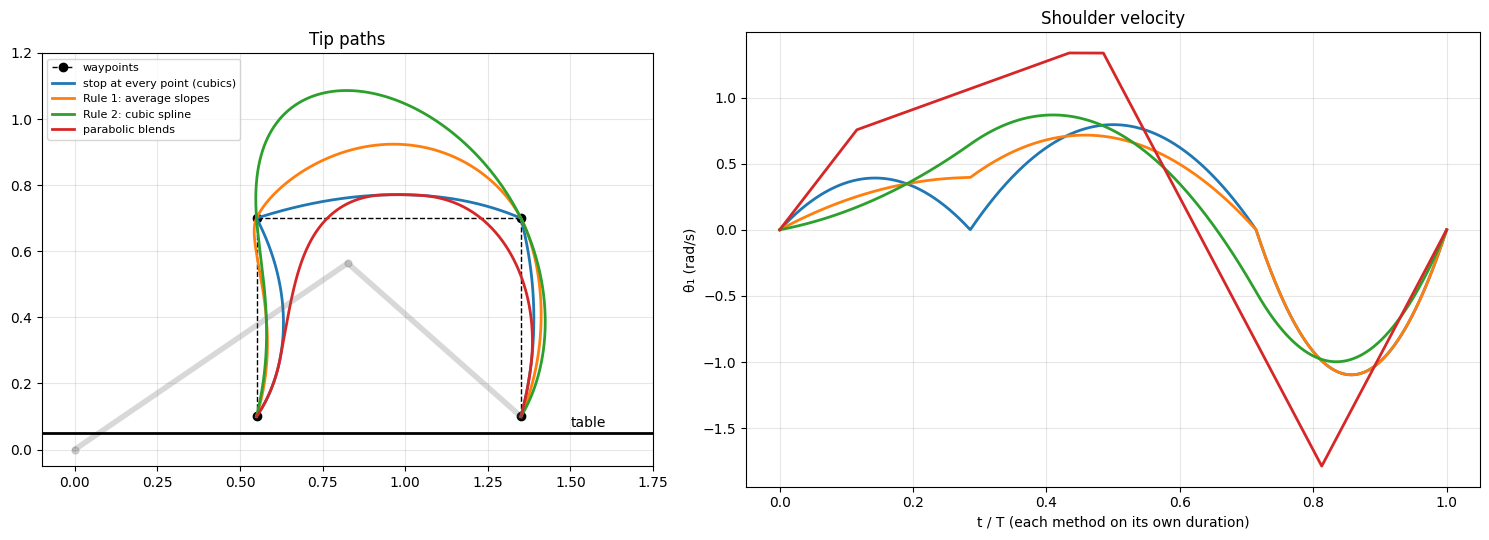

Time to run the same waypoints within v_max = 2.0 rad/s and a_max = 6.0 rad/s²:
  stop at every point (fastest trapezoids)    2.11 s
  stop at every point (cubics)                2.99 s
  Rule 1: average slopes                      2.99 s
  Rule 2: cubic spline                        2.65 s
  parabolic blends                            1.59 s


In [14]:
xy_A, xy_A_up, xy_B_up, xy_B = (1.35, 0.1), (1.35, 0.7), (0.55, 0.7), (0.55, 0.1)
TABLE_Y = 0.05
Q_wp = np.array([ik_2R(*p, elbow=-1) for p in (xy_A, xy_A_up, xy_B_up, xy_B)])   # elbow up
durs_2R = np.array([1.0, 1.5, 1.0])
V_LIM_2R, A_LIM_2R = 2.0, 6.0                                            # rad/s, rad/s²

plans_2R = {name: cubic_segments(Q_wp, durs_2R, V) for name, V in [
    ('stop at every point (cubics)', np.zeros_like(Q_wp)),
    ('Rule 1: average slopes', via_velocities_average(Q_wp, durs_2R)),
    ('Rule 2: cubic spline', via_velocities_spline(Q_wp, durs_2R))]}
plans_2R['parabolic blends'] = parabolic_blends(Q_wp, *plan_blends(Q_wp, V_LIM_2R, A_LIM_2R))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.2]})
ax = axes[0]
ax.plot(*np.array([xy_A, xy_A_up, xy_B_up, xy_B]).T, 'k--o', lw=1, ms=6, label='waypoints')
for name, (traj, T) in plans_2R.items():
    t, q, qd, qdd = sample(traj, T, 1501)
    ax.plot(*fk_2R(q)[1].T, lw=2, label=name)
    axes[1].plot(t / T, qd[:, 0], lw=2, label=name)
draw_2R(ax, Q_wp[0], alpha=0.25)
ax.axhline(TABLE_Y, color='k', lw=2); ax.text(1.5, TABLE_Y + 0.01, 'table', va='bottom')
ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.set_xlim(-0.1, 1.75); ax.set_ylim(-0.05, 1.2)
ax.legend(fontsize=8, loc='upper left'); ax.set_title('Tip paths')
axes[1].set_xlabel('t / T (each method on its own duration)'); axes[1].set_ylabel('θ̇₁ (rad/s)')
axes[1].grid(alpha=0.3); axes[1].set_title('Shoulder velocity')
plt.tight_layout(); plt.show()

print(f'Time to run the same waypoints within v_max = {V_LIM_2R} rad/s and a_max = {A_LIM_2R} rad/s²:')
stops = sum(sync_trapezoid(Q_wp[k], Q_wp[k + 1], V_LIM_2R, A_LIM_2R)[0] for k in range(3))
print(f"  {'stop at every point (fastest trapezoids)':<42} {stops:5.2f} s")
for name, (traj, T) in plans_2R.items():
    t, q, qd, qdd = sample(traj, T, 3001)
    k = max(np.abs(qd).max() / V_LIM_2R, np.sqrt(np.abs(qdd).max() / A_LIM_2R))   # scaling law, Section 8.1
    print(f"  {name:<42} {T * k:5.2f} s")

Three lessons:

1. **Smoothest in time is not best in space.** The spline has the smoothest joint motion, yet
   its tip path swings far above the via points (to $y \approx 1.09$ m) and out past $A$ near the pick point,
   where a neighbouring object would be hit. Rule 1 bulges less. The parabolic blends rise
   no higher than stopping at every point (both reach $y \approx 0.77$ m on the carry),
   but they cut the corners hard: with these limits the tip passes
   8.6 cm from $A'$ and 17.7 cm from $B'$ (the explorer below prints these distances).
2. **Even "stop at every point" is not straight.** All four methods interpolate joint angles,
   so the vertical lifts and descents come out curved, most of all near $B$, close to the base
   (Section 8.5 explains why and shows how to get straight lines).
3. **Not stopping is faster.** Within the same limits, the blends need about a quarter less time
   than the fastest stop-at-every-point trapezoids (1.59 s vs 2.11 s), because they keep moving
   through the corners and cruise at the speed limit. The cubic methods are slower still: their
   hand-picked segment durations, stretched by the scaling law until the limits hold, do not use
   the limits well.

Whatever the method, **check the path with forward kinematics** before running it, as we did
here: plot the gripper path and compare it with the table and the objects around it.

**Explore the blends.** The sliders set the limits. Lower the acceleration limit and watch the
corners round off more; raise the speed limit and the corners round off more too, because
faster segments need longer blends to turn.

In [15]:
def explore_blends():
    def _view(v_max=2.0, a_max=6.0):
        Tk, tb = plan_blends(Q_wp, v_max, a_max)
        traj, T = parabolic_blends(Q_wp, Tk, tb)
        t, q, _, _ = sample(traj, T, 1501)
        tip = fk_2R(q)[1]
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.plot(*np.array([xy_A, xy_A_up, xy_B_up, xy_B]).T, 'k--o', lw=1, ms=6)
        ax.plot(*tip.T, lw=2.5, color='tab:red')
        ax.axhline(TABLE_Y, color='k', lw=2)
        miss = [np.min(np.linalg.norm(tip - np.array(p), axis=1)) for p in (xy_A_up, xy_B_up)]
        ax.set_title(f'T = {T:.2f} s;  tip passes {100 * miss[0]:.1f} cm from A\', {100 * miss[1]:.1f} cm from B\'')
        ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.set_xlim(0.2, 1.7); ax.set_ylim(0.0, 1.0)
        plt.show()

    interact(_view,
             v_max=FloatSlider(value=2.0, min=0.5, max=4.0, step=0.1, description='v_max (rad/s)'),
             a_max=FloatSlider(value=6.0, min=1.0, max=20.0, step=0.5, description='a_max (rad/s²)'))


explore_blends()

interactive(children=(FloatSlider(value=2.0, description='v_max (rad/s)', max=4.0, min=0.5), FloatSlider(value…

### 8.4.4  Where the robot must stop

Not stopping saves time, but some waypoints still need the arm at rest:

- **Grasp and release.** The gripper closes or opens while the arm holds still; a block grabbed
  on the move slides or tips.
- **Contact and precise placement.** Setting a block on a stack, or anything that touches,
  ends at rest, ideally with a short, slow final approach.
- **Every other waypoint** (above the pick, above the goal, points that steer around obstacles)
  can be a via point.

When a waypoint becomes a via point, the path near it changes: blends cut the corner
(Section 8.4.2) and cubics can bulge (Section 8.4.3). If the via point was there to give
clearance, for example to lift a block 6 cm before moving sideways, raise it by the amount the
corner is cut, or plan the blend with a smaller speed or a larger acceleration, and check the
result with forward kinematics.

> **Key Takeaways — Section 8.4**
> - Stop only where the task needs it (grasp, release, contact); pass every other waypoint as a via point.
> - Cubic segments with via velocities pass exactly through the points with continuous velocity. Rule 1: average the neighbouring slopes, or 0 where the joint turns back. Rule 2 (cubic spline): a tridiagonal system that also makes the acceleration continuous.
> - Linear segments with parabolic blends: cruise between points, blend around them; the miss at a via point is $(V_k - V_{k-1})t_b/8$, or $\Delta V^2/(8a_{\max})$ with the shortest blend. Plan $T_k$ from $v_{\max}$ and $t_b$ from $a_{\max}$, with one blend time for all joints.
> - Smoothest in time is not best in space: always check the gripper path with forward kinematics.

## 8.5  Straight-Line Trajectories in Task Space

### 8.5.1  Joint space is not task space

Every trajectory so far interpolates **joint angles**, and the gripper follows whatever curve
the forward kinematics makes of them. Section 8.4.3 showed curved "vertical" lifts on the 2R
arm. On the SO-ARM101, the same happens for the two moves of a pick and place, with the
gripper pointing straight down:

- the **descent** from 6 cm above the pick spot down to the grasp height, and
- the **carry** from 6 cm above the pick spot to 6 cm above the place spot.

<p align="center"><img src="Fig8-04_joint_vs_line.png" width="900"></p>

<p align="center"><i>Figure 8.4 — SO-ARM101 seen from above. (a) Interpolating the joints swings the gripper in an arc around the pan axis (blue); a straight line needs IK at every sample (red). (b) The same gripper speed v on lines closer to the pan axis needs a faster pan joint: θ̇<sub>1,max</sub> = v/d (Section 8.5.3).</i></p>

Figure 8.4(a) shows the carry. The cell runs both moves as joint-space cubics and measures how far
the gripper point strays from the straight line between the ends.

joint-space descent : the gripper point strays up to   3.0 mm from the straight line
joint-space carry   : the gripper point strays up to  11.3 mm from the straight line


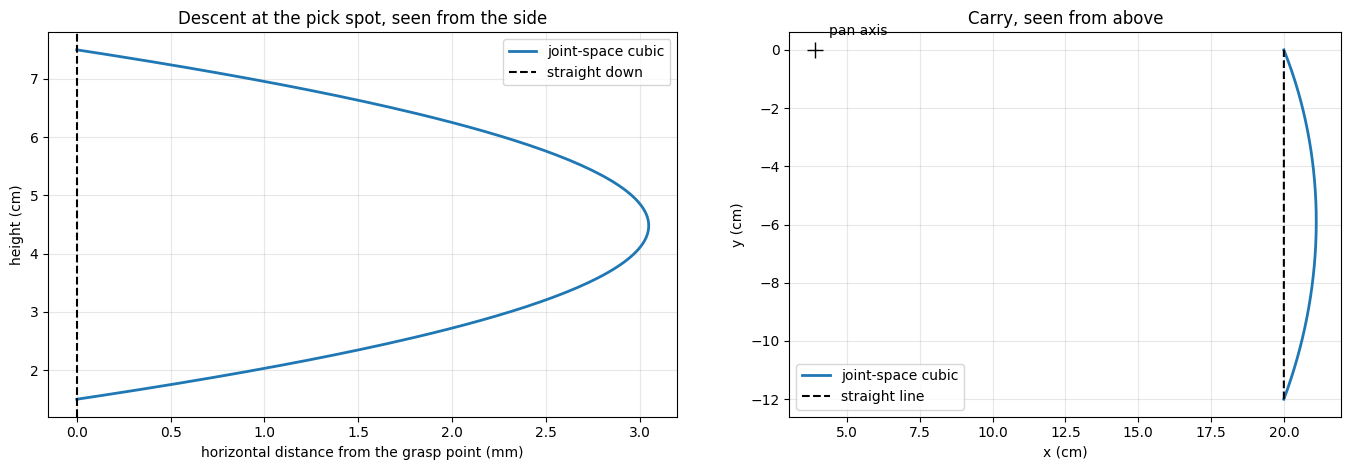

In [16]:
def gripper_path(traj, T, n=200):
    # Gripper point o_e along a trajectory, from the forward kinematics; (n, 3) array
    return np.array([so101.fk(traj(t)[0])[:3, 3] for t in np.linspace(0, T, n)])


def distance_from_line(points, a, b):
    # Distance of each point from the straight line through a and b
    u = (b - a) / np.linalg.norm(b - a)
    d = points - a
    return np.linalg.norm(d - np.outer(d @ u, u), axis=1)


q_above_pick, q_grasp = so101_top_down(PICK_XY, Z_GRASP + LIFT), so101_top_down(PICK_XY, Z_GRASP)
q_above_place = so101_top_down(PLACE_XY, Z_GRASP + LIFT)
joint_moves = {'descent': cubic_segments([q_above_pick, q_grasp], [1.0], np.zeros((2, 5))),
               'carry': cubic_segments([q_above_pick, q_above_place], [1.0], np.zeros((2, 5)))}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for name, (traj, T) in joint_moves.items():
    path = gripper_path(traj, T)
    off = distance_from_line(path, path[0], path[-1])
    print(f'joint-space {name:<8}: the gripper point strays up to {1000 * off.max():5.1f} mm from the straight line')
desc = gripper_path(*joint_moves['descent'])
axes[0].plot(1000 * np.hypot(*(desc[:, :2] - desc[-1, :2]).T), 100 * desc[:, 2], lw=2, label='joint-space cubic')
axes[0].axvline(0, color='k', ls='--', label='straight down')
axes[0].set_xlabel('horizontal distance from the grasp point (mm)'); axes[0].set_ylabel('height (cm)')
axes[0].set_title('Descent at the pick spot, seen from the side')
carry = gripper_path(*joint_moves['carry'])
axes[1].plot(100 * carry[:, 0], 100 * carry[:, 1], lw=2, label='joint-space cubic')
axes[1].plot(100 * carry[[0, -1], 0], 100 * carry[[0, -1], 1], 'k--', label='straight line')
axes[1].plot(100 * geo.xp, 0, 'k+', ms=12); axes[1].text(100 * geo.xp + 0.5, 0.5, 'pan axis')
axes[1].set_xlabel('x (cm)'); axes[1].set_ylabel('y (cm)'); axes[1].set_aspect('equal')
axes[1].set_title('Carry, seen from above')
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

The carry swings in an **arc around the pan axis**: interpolating the joints keeps the reach
roughly constant while the pan joint turns. The descent drifts a few millimetres sideways and
comes back. A few millimetres matter when the fingers must come down around a 1-inch block
with a few millimetres to spare.

### 8.5.2  Interpolating the gripper position

To move the gripper along a straight line, interpolate the **gripper position** and let the
inverse kinematics find the joint angles at every instant:

$$\mathbf{p}(t) = \mathbf{p}_0 + s(t)\,(\mathbf{p}_f - \mathbf{p}_0), \qquad
\boldsymbol\theta(t) = \mathrm{IK}\big(\mathbf{p}(t)\big).$$

Any time scaling of Sections 8.2 and 8.3 can be used for $s(t)$. The orientation is
interpolated the same way. For the SO-ARM101 that is just the pitch,
$\varphi(t) = \varphi_0 + s(t)(\varphi_f - \varphi_0)$ (constant $-90^\circ$ here). For a full
orientation, turn about one fixed axis: if $(\hat{\mathbf{k}}, \alpha)$ is the axis-angle form
(Section 4.3.3) of the rotation $\mathbf{R}_0^\top\mathbf{R}_f$ from the start to the goal, use
$\mathbf{R}(t) = \mathbf{R}_0\,\mathbf{R}_{\hat{\mathbf{k}}}\big(s(t)\,\alpha\big)$, which is the same as
quaternion SLERP.

Three checks, at **every** sample, not just at the ends:

1. **Reachable:** every point of the line must be inside the workspace.
2. **Within the joint limits.**
3. **Same branch:** the IK must keep choosing the same solution (elbow up, facing the target).
   Switching branches mid-line makes the joints jump.

In [17]:
def so101_line(p0, pf, T, phi=PHI_DOWN):
    # Straight line of the gripper point from p0 to pf in T seconds, cubic time scaling, constant pitch.
    # Returns traj(t) -> (q, qd, qdd); velocities and accelerations by finite differences.
    p0, pf = np.asarray(p0, float), np.asarray(pf, float)
    a = cubic_coefficients(0.0, 1.0, T)

    def q_at(t):
        q = so101_ik(p0 + poly_eval(a, min(max(t, 0.0), T))[0] * (pf - p0), phi)
        assert q is not None and so101.within_limits(q), f'line leaves the workspace at t = {t:.3f} s'
        return q

    def traj(t, h=1e-4):
        q_minus, q_now, q_plus = q_at(t - h), q_at(t), q_at(t + h)
        return q_now, (q_plus - q_minus) / (2 * h), (q_plus - 2 * q_now + q_minus) / h**2
    return traj


p_above_pick, p_grasp = np.array([*PICK_XY, Z_GRASP + LIFT]), np.array([*PICK_XY, Z_GRASP])
p_above_place = np.array([*PLACE_XY, Z_GRASP + LIFT])
line_moves = {'descent': (so101_line(p_above_pick, p_grasp, 1.0), 1.0),
              'carry': (so101_line(p_above_pick, p_above_place, 1.0), 1.0)}

for name in ('descent', 'carry'):
    for kind, (traj, T) in (('joint space', joint_moves[name]), ('straight line', line_moves[name])):
        t, q, qd, qdd = sample(traj, T, 401)
        path = gripper_path(traj, T)
        off = distance_from_line(path, path[0], path[-1]).max()
        print(f'{name:<8} {kind:<14} off the line {1000 * off:6.2f} mm   peak joint speeds (°/s): '
              + ' '.join(f'{v:6.1f}' for v in np.degrees(np.abs(qd).max(axis=0)[:4])))

descent  joint space    off the line   3.05 mm   peak joint speeds (°/s):    0.0    6.3   30.2   36.6
descent  straight line  off the line   0.00 mm   peak joint speeds (°/s):    0.0    9.8   32.1   36.5
carry    joint space    off the line  11.27 mm   peak joint speeds (°/s):   55.0   30.6   36.0    5.4
carry    straight line  off the line   0.00 mm   peak joint speeds (°/s):   57.7   39.6   47.8    9.3


Both straight lines are straight to within a hundredth of a millimetre (what remains is the
0.01 mm sideways offset that Section 7.4.5 removes). For the same 1-second carry the straight
line asks more of the shoulder and elbow, which must pull the gripper in toward the base and
push it out again instead of letting it swing around in an arc.

### 8.5.3  Joint speeds along a line, and choosing $T$

Differentiating $\mathbf{p}(t)$ gives the gripper velocity $\dot{\mathbf{p}} = (\mathbf{p}_f - \mathbf{p}_0)\,\dot s$,
and the joint velocities follow from the inverse velocity relation of Section 6.6.1,

$$\dot{\boldsymbol\theta} = \mathbf{J}^{-1}(\boldsymbol\theta)\,\dot{\mathbf{p}} .$$

A straight-line trajectory is the resolved-rate motion of Chapter 6 with a time-scaled
velocity. Near a singularity $\mathbf{J}$ is nearly singular, and even a slow gripper needs very
fast joints (Path B in Section 6.6.1). For the SO-ARM101 there is a simple special case: a
horizontal line that passes at distance $d$ from the pan axis, travelled at speed $v$, turns the
pan joint at

$$\dot\theta_1 = \frac{v\,d}{r^2} \quad\Longrightarrow\quad |\dot\theta_1|_{\max} = \frac{v}{d}\ \text{ at the closest point } (r = d).$$

Lines that pass close to the base need a fast pan joint (Figure 8.4(b)). The cell checks the formula on three
parallel 20 cm lines, each run in 1 s, 3 cm above the grasp height.

In [18]:
print(f"{'distance d (cm)':>16} {'peak gripper speed (m/s)':>25} {'peak pan speed (°/s)':>21} {'v/d (°/s)':>10}")
for d in (0.20, 0.12, 0.08):
    x = geo.xp + d
    traj = so101_line([x, -0.10, Z_GRASP + 0.03], [x, 0.10, Z_GRASP + 0.03], 1.0)
    t, q, qd, qdd = sample(traj, 1.0, 801)
    v_peak = 1.5 * 0.20 / 1.0                                            # cubic: 1.5 Δ/T
    print(f'{100 * d:16.0f} {v_peak:25.2f} {np.degrees(np.abs(qd[:, 0]).max()):21.1f} {np.degrees(v_peak / d):10.1f}')

 distance d (cm)  peak gripper speed (m/s)  peak pan speed (°/s)  v/d (°/s)


              20                      0.30                  85.9       85.9
              12                      0.30                 143.2      143.2
               8                      0.30                 214.9      214.9


The formula matches the simulated peaks exactly. The same gripper speed that needs 86°/s of
pan speed 20 cm from the axis needs 215°/s at 8 cm, more than our 180°/s limit: that line must
be run more slowly, or moved away from the base.

**Choosing $T$ for a line.** The joint speeds of a straight line change along it, so there is no
closed-form $T_{\min}$ as in Section 8.2.4. The scaling law of Section 8.1 still holds, because
the shape of the motion does not change when $T$ does: sample the trajectory once, find the peak
joint speed and acceleration, and stretch it by
$k = \max\big(\text{peak speed}/v_{\max},\ \sqrt{\text{peak acceleration}/a_{\max}}\big)$.

In [19]:
def min_duration(make_traj, v_max, a_max, T_try=1.0, n=401):
    # Shortest T for a trajectory family make_traj(T) -> traj, from one trial run and the scaling law
    t, q, qd, qdd = sample(make_traj(T_try), T_try, n)
    return T_try * max(np.abs(qd).max() / v_max, np.sqrt(np.abs(qdd).max() / a_max))


for name, (p0, pf) in {'descent': (p_above_pick, p_grasp), 'carry': (p_above_pick, p_above_place)}.items():
    T_line = min_duration(lambda T: so101_line(p0, pf, T), V_MAX, A_MAX)
    T_joint = sync_trapezoid(so101_top_down(p0[:2], p0[2]), so101_top_down(pf[:2], pf[2]), V_MAX, A_MAX)[0]
    t, q, qd, qdd = sample(so101_line(p0, pf, T_line), T_line, 401)
    print(f'{name:<8}: straight line (cubic timing) {T_line:.3f} s, peak joint speed {np.degrees(np.abs(qd).max()):5.1f}°/s, '
          f'peak acceleration {np.degrees(np.abs(qdd).max()):5.1f}°/s²   |   joint-space trapezoid {T_joint:.3f} s')

descent : straight line (cubic timing) 0.489 s, peak joint speed  74.5°/s, peak acceleration 720.0°/s²   |   joint-space trapezoid 0.368 s
carry   : straight line (cubic timing) 0.658 s, peak joint speed  87.7°/s, peak acceleration 720.0°/s²   |   joint-space trapezoid 0.451 s


The straight line costs some time: it uses cubic timing (Section 8.3.2: a trapezoid needs about 15% less
time), and its joint speeds vary along the line, so the limit is reached only at one
point. Near the table, where the path matters, that is usually worth it.

### 8.5.4  Joint space or task space?

| | Joint-space path | Straight line in task space |
|---|---|---|
| Industrial name | MoveJ (joint move) | MoveL (linear move) |
| Gripper path | a curve (an arc around the base for a carry) | a straight line |
| Needs | IK at the two ends only | IK at every sample, all reachable, same branch |
| Joint speeds | set directly by the time scaling | vary along the line; large near singularities and near the pan axis |
| Speed | fastest for a given limit | slower |
| Use for | large moves through free space | approaching, grasping, lifting, placing |

> **Key Takeaways — Section 8.5**
> - Interpolating joints moves the gripper along a curve: the SO-ARM101 carry swings in an arc around the pan axis, and a "vertical" descent drifts sideways by millimetres.
> - Straight line: $\mathbf{p}(t) = \mathbf{p}_0 + s(t)(\mathbf{p}_f - \mathbf{p}_0)$, $\boldsymbol\theta(t) = \mathrm{IK}(\mathbf{p}(t))$; orientation about a fixed axis (axis-angle, SLERP). Check reachability, limits and branch at every sample.
> - Joint speeds: $\dot{\boldsymbol\theta} = \mathbf{J}^{-1}\dot{\mathbf{p}}$; large near singularities. For the SO-ARM101 pan joint, $|\dot\theta_1|_{\max} = v/d$.
> - Choose $T$ by sampling once and applying the scaling law. Straight lines near objects, joint-space moves through free space.

## 8.6  From a Trajectory to Motor Commands

A trajectory is a function $\boldsymbol\theta(t)$, but a servo only accepts goal positions. Three
layers turn one into the other:

| Layer | Where | How often | What it does |
|---|---|---|---|
| Planner | your program | once per move | chooses the path and the timing (Sections 8.1 to 8.5) |
| Sampler | your program | every $\Delta t$ (for example 20 ms) | evaluates $\boldsymbol\theta(k\,\Delta t)$ and sends it as the goal position of each servo |
| Servo | inside each motor | much faster | its own feedback loop drives the motor toward the latest goal |

<p align="center"><img src="Fig8-05_planner_sampler_servo.png" width="900"></p>

<p align="center"><i>Figure 8.5 — From a trajectory to motion. The planner computes θ(t); the sampler sends θ(kΔt) as the goal every Δt and holds it; the servo follows that staircase with a lag of about t<sub>lag</sub> θ̇.</i></p>

**Sampling.** Between samples the goal is held constant, so the servo sees a staircase that
follows the trajectory. Each step is about $\dot\theta\,\Delta t$: at 100°/s, 2° at 50 Hz but 10°
at 10 Hz. Coarser steps make the motion jerkier and add delay, because on average the goal is
already $\Delta t/2$ old.

**Tracking.** A position servo needs an error to make torque, so it lags behind a moving goal.
A simple model: the servo closes the gap with a time constant $t_{\text{lag}}$,
$\dot\theta_m = (\theta_{\text{goal}} - \theta_m)/t_{\text{lag}}$. For a goal moving at speed $\dot\theta$
the error settles at $t_{\text{lag}}\,\dot\theta$. The cell uses $t_{\text{lag}} = 15$ ms, about what
the SO-101's simulated servos show, and a 75° move in 1 s.

trajectory   rate  peak error (°)  error at t = T (°)
linear       50 Hz            2.03                2.03
linear       10 Hz            7.52                7.51


cubic        50 Hz            3.05                0.20


cubic        10 Hz           11.12                2.11


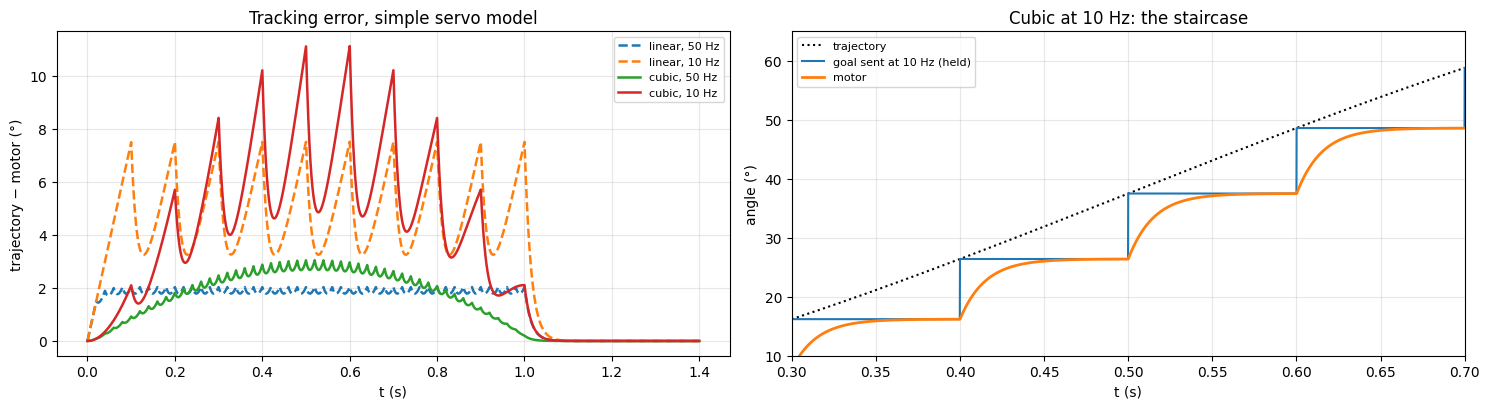

In [20]:
def servo_response(trajectory_q, T, dt_sample, t_lag=0.015, t_after=0.4, h=1e-4):
    # Simple servo model: the goal is sampled every dt_sample and held; the motor follows with time constant t_lag.
    t = np.arange(0, T + t_after, h)
    goal = np.array([trajectory_q(np.floor(ti / dt_sample) * dt_sample) for ti in t])   # sample and hold
    motor = np.zeros_like(t)
    motor[0] = goal[0]
    for k in range(1, len(t)):
        motor[k] = motor[k - 1] + h * (goal[k - 1] - motor[k - 1]) / t_lag
    exact = np.array([trajectory_q(ti) for ti in t])
    return t, goal, motor, exact


D, T = 75.0, 1.0
linear_q = lambda t: D * min(max(t / T, 0.0), 1.0)
cubic_q = lambda t: poly_eval(cubic_coefficients(0.0, D, T), min(max(t, 0.0), T))[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
print(f"{'trajectory':<10} {'rate':>6} {'peak error (°)':>15} {'error at t = T (°)':>19}")
for name, traj_q, ls in (('linear', linear_q, '--'), ('cubic', cubic_q, '-')):
    for hz in (50, 10):
        t, goal, motor, exact = servo_response(traj_q, T, 1 / hz)
        err = exact - motor
        axes[0].plot(t, err, ls, lw=1.8, label=f'{name}, {hz} Hz')
        print(f'{name:<10} {hz:4d} Hz {np.abs(err[t <= T]).max():15.2f} {err[np.argmin(np.abs(t - T))]:19.2f}')
t, goal, motor, exact = servo_response(cubic_q, T, 1 / 10)
axes[1].plot(t, exact, 'k:', lw=1.5, label='trajectory')
axes[1].plot(t, goal, lw=1.5, label='goal sent at 10 Hz (held)')
axes[1].plot(t, motor, lw=2, label='motor')
axes[0].set_ylabel('trajectory − motor (°)'); axes[0].set_title('Tracking error, simple servo model')
axes[1].set_ylabel('angle (°)'); axes[1].set_title('Cubic at 10 Hz: the staircase'); axes[1].set_xlim(0.3, 0.7); axes[1].set_ylim(10, 65)
for ax in axes:
    ax.set_xlabel('t (s)'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

At 50 Hz the model shows the pattern a real servo shows. The linear trajectory's error jumps as
soon as the move starts, and the motor is still 2° behind, and still moving, at $t = T$. The
cubic's error grows and shrinks with its speed: its peak is larger, because its peak speed is
1.5 times linear's, but it comes in the middle of the move, and at $t = T$ the motor is almost
on target and at rest. (This first-order model leaves out the overshoot a real servo shows
when a linear move starts, which makes linear's error at the start even larger.)

At 10 Hz the errors are several times larger: just before each new goal arrives, the goal is a
full sample period old, so the error grows by up to $\dot\theta\,\Delta t$ (7.5° at 75°/s), and the
motor visibly follows a staircase.

**The servo's own profile.** Sent a single goal angle, an STS3215 servo moves there along its
own trapezoidal velocity profile. When the sampler sends a new goal every
20 ms, each goal is only a step of a degree or two, and the built-in profile acts on those
small steps; it no longer shapes the whole move, as long as its acceleration setting is high
(LeRobot sets it high when it connects). Some servos also accept a move time with each goal,
which gives a timed, smooth move from a single command. That is enough for a point-to-point
joint move, but the profile shape is fixed by the servo, and a single command per move cannot
follow a straight line in task space or pass a via point without stopping. That is why the
trajectories of this chapter are streamed from the computer.

> **Key Takeaways — Section 8.6**
> - Planner (once per move), sampler (every $\Delta t$, sends goal positions), servo (fast internal loop).
> - Sampling holds each goal for $\Delta t$: steps of $\dot\theta\,\Delta t$, and about $\Delta t/2$ of extra delay.
> - A position servo lags by roughly $t_{\text{lag}}\,\dot\theta$: smooth trajectories keep that error small at the start and the end of a move.
> - A servo's built-in profile handles one goal at a time; streaming lets the computer choose the shape, the path and the via points.

## 8.7  Putting It Together: A Fast Pick and Place on the SO-ARM101

We now move a block from the pick spot, $(20, -12)$ cm, to the place spot, $(20, 0)$ cm,
with the gripper pointing straight down and a 6 cm lift, and compare three plans. Each
starts and ends 6 cm above a spot, and each spends 0.5 s on closing and 0.5 s on opening the
gripper.

1. **Fixed times**: every move takes a fixed, generous time (1 to 2.5 s), with a hold of 0.5 to 1 s after it.
2. **Stop at every waypoint, as fast as the limits allow:** a synchronized trapezoid
   (Section 8.3.3) for each move.
3. **Via points:** the descent to the block and the final retreat are trapezoids, but lift,
   carry and lower form **one** blended trajectory through the two "above" points
   (Section 8.4.2), stopping only at the block and at the goal.

<p align="center"><img src="Fig8-06_pick_and_place.png" width="900"></p>

<p align="center"><i>Figure 8.6 — Lift, carry and lower. The arm must stop at the grasp and the place, where the gripper acts; the points above them are via points. Blending through them (red) saves time but cuts the corners, so the block starts moving sideways before it is fully lifted. Times from the comparison below, with a<sub>max</sub> = 720°/s².</i></p>

Figure 8.6 shows plan 3 next to stopping at every waypoint. Real limits are rarely the paper values: a block held in the gripper slips if the arm
accelerates too hard. So the comparison runs for three acceleration limits.

In [21]:
GRIP_TIME = 0.5                                                          # s to close, and to open, the gripper
q_pick, q_pick_up = so101_top_down(PICK_XY, Z_GRASP), so101_top_down(PICK_XY, Z_GRASP + LIFT)
q_place, q_place_up = so101_top_down(PLACE_XY, Z_GRASP), so101_top_down(PLACE_XY, Z_GRASP + LIFT)

# Plan 1: fixed move and hold times (descend, close, lift, carry, lower, open, retreat)
T_plan1 = sum([1.5, 1.0, 1.5, 2.5, 1.5, 1.0, 1.5]) + sum([0.5, 1.0, 0.5, 0.5, 0.5, 1.0, 0.5])

print(f'Plan 1, fixed times: {T_plan1:.1f} s\n')
print(f"{'a_max (°/s²)':>12} {'plan 2: stop everywhere':>24} {'plan 3: via points':>19} {'saved':>7}   lift → carry → lower: stop vs blend")
for a_deg in (720, 360, 180):
    a_lim = np.radians(a_deg)
    T_down = sync_trapezoid(q_pick_up, q_pick, V_MAX, a_lim)[0]
    T_up = sync_trapezoid(q_place, q_place_up, V_MAX, a_lim)[0]
    transit_stop = sum(sync_trapezoid(a, b, V_MAX, a_lim)[0]
                       for a, b in [(q_pick, q_pick_up), (q_pick_up, q_place_up), (q_place_up, q_place)])
    transit_blend = parabolic_blends([q_pick, q_pick_up, q_place_up, q_place],
                                     *plan_blends([q_pick, q_pick_up, q_place_up, q_place], V_MAX, a_lim))[1]
    T2 = T_down + GRIP_TIME + transit_stop + GRIP_TIME + T_up
    T3 = T_down + GRIP_TIME + transit_blend + GRIP_TIME + T_up
    print(f'{a_deg:12d} {T2:22.2f} s {T3:17.2f} s {100 * (1 - T3 / T2):6.0f}%   {transit_stop:.2f} s vs {transit_blend:.2f} s')

Plan 1, fixed times: 15.0 s

a_max (°/s²)  plan 2: stop everywhere  plan 3: via points   saved   lift → carry → lower: stop vs blend
         720                   2.94 s              2.58 s     13%   1.20 s vs 0.83 s
         360                   3.75 s              3.23 s     14%   1.69 s vs 1.17 s
         180                   4.89 s              4.15 s     15%   2.40 s vs 1.66 s


Two lessons for a fast pick and place:

- **Time each move from the limits.** Going from fixed, generous times to the fastest moves
  the limits allow is by far the largest gain: from 15 s per block to a few seconds.
- **Then remove the unnecessary stops.** Blending through the two points above the block and
  above the goal saves about 30% of the lift-carry-lower time, and the saving grows as the
  acceleration limit is lowered, because each stop costs more when the arm must slow down
  gently.

The cost of not stopping is the corner. The cell plots the height of the gripper point
against its horizontal distance from the block, for the blended plan and for the
stop-everywhere plan.

a_max = 720°/s²: the gripper is 1 cm sideways from the block when only 4.6 cm above the grasp height (of the 6 cm lift)
a_max = 180°/s²: the gripper is 1 cm sideways from the block when only 4.6 cm above the grasp height (of the 6 cm lift)


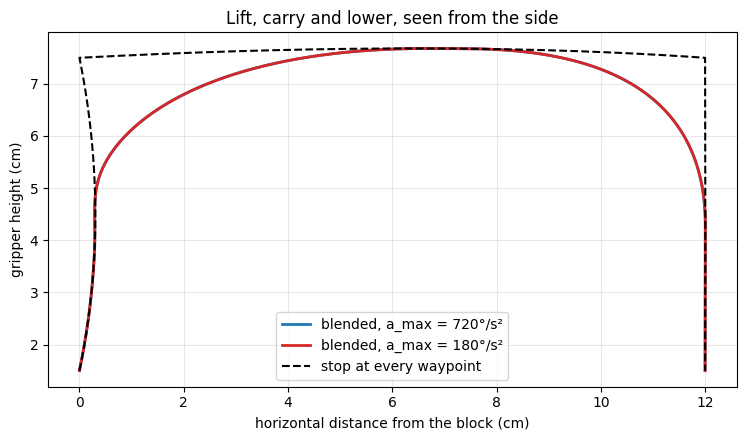

In [22]:
P_transit = np.array([q_pick, q_pick_up, q_place_up, q_place])
fig, ax = plt.subplots(figsize=(10, 4.5))
for a_deg, color in ((720, 'tab:blue'), (180, 'tab:red')):
    traj, T = parabolic_blends(P_transit, *plan_blends(P_transit, V_MAX, np.radians(a_deg)))
    path = gripper_path(traj, T, 600)
    along = np.linalg.norm(path[:, :2] - path[0, :2], axis=1)
    ax.plot(100 * along, 100 * path[:, 2], lw=2, color=color, label=f'blended, a_max = {a_deg}°/s²')
    k = np.argmax(along > 0.01)
    print(f'a_max = {a_deg}°/s²: the gripper is 1 cm sideways from the block when only '
          f'{100 * (path[k, 2] - Z_GRASP):.1f} cm above the grasp height (of the 6 cm lift)')
stops = np.vstack([gripper_path(*cubic_segments(P_transit[k:k + 2], [1.0], np.zeros((2, 5)))) for k in range(3)])
ax.plot(100 * np.linalg.norm(stops[:, :2] - stops[0, :2], axis=1), 100 * stops[:, 2], 'k--', lw=1.5, label='stop at every waypoint')
ax.set_xlabel('horizontal distance from the block (cm)'); ax.set_ylabel('gripper height (cm)')
ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.legend()
ax.set_title('Lift, carry and lower, seen from the side')
plt.tight_layout(); plt.show()

The blend rounds off the top corners, here by about 1.4 cm of the 6 cm lift: the block starts
moving sideways before it is fully lifted. The amount does not depend on the acceleration
limit in this plan, because the planner scales the segment speeds and the blends together. If
neighbouring blocks or a growing stack need the full clearance, raise the via points by the
amount cut, and check again.

**For a fast pick and place**, this is the recipe:

1. Compute every waypoint with IK from the block and goal positions (Chapter 7), and check it against the joint limits (the far spots need a tilted pitch, Section 7.4.4).
2. Decide which waypoints are stops (grasp, release, placing on a stack) and which are via points.
3. Time every move from measured speed and acceleration limits, not from guesses: trapezoids for moves that stop, blends through via points.
4. Use straight lines (Section 8.5) where the path near a block matters; joint-space moves elsewhere.
5. Check every gripper path with FK against the table, the waiting blocks and the stack, then simulate it before running it on the robot.

## Chapter 8 Summary

> - **Path vs trajectory:** a trajectory is a path $\boldsymbol\theta(s)$ plus a time scaling $s(t)$. On a straight joint-space path every joint uses the same $s(t)$: $\dot\theta_i = \Delta_i\dot s$. Stretching time by $k$ divides velocities by $k$ and accelerations by $k^2$.
> - **Polynomials:** linear (velocity jumps), cubic (four conditions; rest to rest $3u^2 - 2u^3$, peak $1.5\Delta/T$, $\pm6\Delta/T^2$), quintic (six conditions; $10u^3 - 15u^4 + 6u^5$, continuous acceleration). $T_{\min} = \max(c_v|\Delta|/v_{\max}, \sqrt{c_a|\Delta|/a_{\max}})$.
> - **Trapezoid (LSPB):** $T = |\Delta|/v + v/a$; with $v_{\max}$, $a_{\max}$ the fastest rest-to-rest move. Synchronize joints with $\dot s_{\max} = \min v_{\max,i}/|\Delta_i|$, $\ddot s_{\max} = \min a_{\max,i}/|\Delta_i|$.
> - **Via points:** cubic segments with via velocities (average-slope rule, or the spline's tridiagonal system for continuous acceleration), or linear segments with parabolic blends (miss $\Delta V\,t_b/8$). Stop only where the task needs it, and check the path with FK.
> - **Task space:** $\boldsymbol\theta(t) = \mathrm{IK}(\mathbf{p}(t))$ for straight lines; $\dot{\boldsymbol\theta} = \mathbf{J}^{-1}\dot{\mathbf{p}}$ grows near singularities (and near the pan axis, $v/d$).
> - **Execution:** sample every $\Delta t$ and stream goal positions; the servo lags by about $t_{\text{lag}}\dot\theta$.

| Method | Passes through the points | Stops at the points | Continuous | Chooses $T$ from limits |
|---|---|---|---|---|
| Linear | yes | yes | position | no (infinite acceleration) |
| Cubic, rest to rest | yes | yes | velocity | $T_{\min}$ formula |
| Quintic, rest to rest | yes | yes | acceleration | $T_{\min}$ formula |
| Trapezoid | yes | yes | velocity | yes, fastest |
| Cubic segments, average-slope velocities | yes | only where a joint turns back | velocity | scaling law |
| Cubic spline | yes | no (except the ends) | acceleration | scaling law |
| Parabolic blends | no (cuts corners) | no (except the ends) | velocity | yes |
| Straight line in task space | yes, along a line | yes | as its $s(t)$ | sample + scaling law |

### Practice problems

1. A joint moves from $10^\circ$ to $70^\circ$ in $T = 2$ s, starting at rest and ending at $20^\circ$/s. Find the cubic coefficients by hand and check them with `cubic_coefficients`. Does the joint overshoot $70^\circ$?
2. Show that the rest-to-rest cubic has peak velocity $1.5\Delta/T$ and end accelerations $\pm6\Delta/T^2$, and that the rest-to-rest quintic has peak velocity $\tfrac{15}{8}\Delta/T$.
3. Trapezoid: a joint must move $120^\circ$ with $v_{\max} = 150^\circ$/s and $a_{\max} = 500^\circ$/s². Find $T$ and $t_b$. Is the profile a trapezoid or a triangle? Then find $t_b$ and the cruise speed for a move of exactly $T = 1.5$ s with $a = 500^\circ$/s².
4. Two joints move $\Delta = (90^\circ, -30^\circ)$. Joint 1 has limits $180^\circ$/s and $720^\circ$/s²; joint 2, $40^\circ$/s and $360^\circ$/s². Which joint sets the pace of a synchronized trapezoid, and what is $T$?
5. Via points: one joint passes $0^\circ, 50^\circ, 20^\circ, 60^\circ$ at $t = 0, 1, 2, 3$ s. Find the via velocities with the average-slope rule and with the spline (solve the $2\times2$ system by hand), and compare with `via_velocities_average` and `via_velocities_spline`.
6. A blend turns a joint from $+100^\circ$/s to $-60^\circ$/s with $a_{\max} = 400^\circ$/s². How long is the blend, and by how much does the joint miss the via point?
7. SO-ARM101: a straight carry passes 6 cm from the pan axis with a peak gripper speed of 0.25 m/s. What pan speed does it need, and is it within $180^\circ$/s? What could you change?
8. Extend Section 8.7 to stacking six blocks into a pyramid (three on the table, two on them, one on top): list the waypoints for one block, mark which are stops, and estimate the total time with the plan-3 numbers. Which waypoints need extra clearance as the pyramid grows?